In [1]:
import pandas as pd
import sys
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold,GridSearchCV
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,accuracy_score,classification_report,
    brier_score_loss,roc_curve
)
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

In [2]:
# The notebook is assumed to be in the project root.
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.model import (
    LoanTypeMedianImputer,
    EmploymentYearsMedianImputer,
#     HierarchicalDPDImputer,
    save_model_artifacts,
    load_model_artifacts,
    predict_default_probability,
)

print("Project root:", PROJECT_ROOT)
print("Custom imputers imported from src.model")


Project root: C:\Users\ESHIKA\Documents\essex_assign
Custom imputers imported from src.model


In [3]:
def loader(path):
    df=pd.read_csv(path)
    print("*********head**********")
    print(df.head())
    print("\n*********columns**********")
    print(df.columns)
    return df

In [4]:
bureau_credit=loader(f"{PROJECT_ROOT}\\data\\raw\\bureau_credit.csv")

*********head**********
   bureau_id customer_id       credit_type lender_category  sanctioned_amount  \
0  BUR300001  CUST100001         Auto Loan            NBFC            7111.82   
1  BUR300002  CUST100001     Personal Loan            Bank           44920.95   
2  BUR300003  CUST100001  Retail Financing            NBFC           28440.17   
3  BUR300004  CUST100002  Retail Financing     Cooperative           39112.28   
4  BUR300005  CUST100002  Retail Financing         Fintech           34835.55   

   outstanding_amount account_status  days_past_due date_opened date_closed  
0             1177.60         Active           36.0  2022-07-30         NaN  
1            33952.82         Active           40.0  2024-06-10         NaN  
2            24777.90         Active           42.0  2018-06-04         NaN  
3            34998.94         Active            8.0  2018-03-15         NaN  
4                0.00         Closed            0.0  2025-12-20  2029-04-05  

*********columns****

In [5]:
collections_events=loader(f"{PROJECT_ROOT}\\data\\raw\\collections_events.csv")

*********head**********
  collection_event_id account_id  event_date    action_type           outcome  \
0           COL400001  ACC210780  2022-07-07    Field Visit         Escalated   
1           COL400002  ACC213329  2021-10-31  Reminder Call          Disputed   
2           COL400003  ACC213329  2023-02-08   Legal Notice    Promise to Pay   
3           COL400004  ACC213329  2021-03-21    Field Visit  Payment Received   
4           COL400005  ACC212150  2022-11-13  Reminder Call  Payment Received   

   amount_recovered  
0               0.0  
1               0.0  
2               0.0  
3            1114.7  
4               0.0  

*********columns**********
Index(['collection_event_id', 'account_id', 'event_date', 'action_type',
       'outcome', 'amount_recovered'],
      dtype='str')


In [6]:
customers=loader(f"{PROJECT_ROOT}\\data\\raw\\customers.csv")

*********head**********
  customer_id  age  gender marital_status education_level employment_type  \
0  CUST100000   41  Female        Married      Vocational  Business Owner   
1  CUST100001   27    Male         Single     High School      Unemployed   
2  CUST100002   46  Female        Married      Vocational  Business Owner   
3  CUST100003   48    Male        Widowed      Vocational      Unemployed   
4  CUST100004   21    Male       Divorced      Bachelor's  Business Owner   

  occupation_sector  years_employed  annual_income   region city_tier  \
0      Construction             2.8        87700.0     West    Tier 3   
1        Healthcare             0.0        12000.0  Central    Tier 1   
2           Finance            30.3        60100.0  Central    Tier 1   
3            Retail             0.0        39500.0     West    Tier 3   
4           Finance             0.5        98500.0  Central    Tier 2   

   num_dependents        housing_type  years_at_residence customer_since  

In [7]:
loan_acc=loader(f"{PROJECT_ROOT}\\data\\raw\\loan_accounts.csv")

*********head**********
  account_id customer_id      loan_type        loan_purpose  loan_amount  \
0  ACC200001  CUST100000       Mortgage             Wedding    306310.51   
1  ACC200002  CUST100001      Auto Loan    Home Improvement     33921.61   
2  ACC200003  CUST100002  Personal Loan  Business Expansion      4469.93   
3  ACC200004  CUST100003  Personal Loan             Medical     26274.80   
4  ACC200005  CUST100003  Personal Loan    Vehicle Purchase     16356.86   

   interest_rate_pct  tenure_months origination_date disbursal_channel  \
0               6.06            360       2022-10-18            Branch   
1               5.52             60       2022-12-19            Online   
2              10.98             48       2023-11-08        Mobile App   
3               7.43             48       2020-04-06       Partner/DSA   
4              10.63             36       2023-04-15            Online   

   collateral_flag  target_default  
0                1               1  


In [8]:
repayment_history=loader(f"{PROJECT_ROOT}\\data\\raw\\repayment_history.csv")

*********head**********
  account_id  payment_month  emi_due  emi_paid  days_past_due payment_status  \
0  ACC200001              1  1848.32   1848.32              0        On-Time   
1  ACC200001              2  1848.32   1848.32             14           Late   
2  ACC200001              3  1848.32   1848.32              7           Late   
3  ACC200001              4  1848.32   1848.32              0        On-Time   
4  ACC200001              5  1848.32   1848.32              0        On-Time   

   outstanding_balance  
0            305201.52  
1            304092.53  
2            302983.53  
3            301874.54  
4            300765.55  

*********columns**********
Index(['account_id', 'payment_month', 'emi_due', 'emi_paid', 'days_past_due',
       'payment_status', 'outstanding_balance'],
      dtype='str')


In [9]:
# 1. Parse origination dates
loan_acc["origination_date"] = pd.to_datetime(
    loan_acc["origination_date"],
    errors="coerce"
)

# 2. Ensure one origination date per account before merging
if loan_acc["account_id"].duplicated().any():
    raise ValueError(
        "loan_acc contains duplicate account_id values. "
        "Resolve duplicates before merging."
    )

# 3. Ensure payment_month remains a numeric month index
repayment_history["payment_month"] = pd.to_numeric(
    repayment_history["payment_month"],
    errors="coerce"
)

# Check for invalid month indices: they should be positive integers
month_values = repayment_history["payment_month"]
invalid_month = (
    month_values.notna()
    & (
        (month_values < 1)
        | (month_values % 1 != 0)
    )
)

if invalid_month.any():
    print(
        f"Warning: {invalid_month.sum()} rows have invalid "
        "payment_month values."
    )

# 4. Join origination date without duplicating repayment rows
# Remove an old copy if rerunning this cell
repayment_history = repayment_history.drop(
    columns=["origination_date"],
    errors="ignore"
)

repayment_history = repayment_history.merge(
    loan_acc[["account_id", "origination_date"]],
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator="_origination_merge"
)

# Check unmatched repayment accounts
unmatched = (
    repayment_history["_origination_merge"] == "left_only"
).sum()

if unmatched:
    print(f"Warning: {unmatched} repayment rows have no matching loan account.")

repayment_history = repayment_history.drop(
    columns="_origination_merge"
)

# 5. Reconstruct approximate monthly dates
# ASSUMPTION: payment_month=1 corresponds to origination month.
valid_month = (
    month_values.notna()
    & (month_values >= 1)
    & (month_values % 1 == 0)
    & repayment_history["origination_date"].notna()
)

repayment_history["payment_date_reconstructed"] = pd.NaT

repayment_history.loc[valid_month, "payment_date_reconstructed"] = [
    origination + pd.DateOffset(months=int(month) - 1)
    for origination, month in zip(
        repayment_history.loc[valid_month, "origination_date"],
        repayment_history.loc[valid_month, "payment_month"]
    )
]

# 6. Inspect the output
print(
    repayment_history[
        [
            "account_id",
            "payment_month",
            "origination_date",
            "payment_date_reconstructed"
        ]
    ].head(10)
)

print(
    "Missing reconstructed dates:",
    repayment_history["payment_date_reconstructed"].isna().sum()
)


  account_id  payment_month origination_date payment_date_reconstructed
0  ACC200001              1       2022-10-18                 2022-10-18
1  ACC200001              2       2022-10-18                 2022-11-18
2  ACC200001              3       2022-10-18                 2022-12-18
3  ACC200001              4       2022-10-18                 2023-01-18
4  ACC200001              5       2022-10-18                 2023-02-18
5  ACC200001              6       2022-10-18                 2023-03-18
6  ACC200001              7       2022-10-18                 2023-04-18
7  ACC200001              8       2022-10-18                 2023-05-18
8  ACC200001              9       2022-10-18                 2023-06-18
9  ACC200001             10       2022-10-18                 2023-07-18
Missing reconstructed dates: 0


In [10]:
customers.isna().sum()

customer_id             0
age                     0
gender                  0
marital_status          0
education_level         0
employment_type         0
occupation_sector       0
years_employed        500
annual_income           0
region                  0
city_tier               0
num_dependents        500
housing_type            0
years_at_residence    500
customer_since          0
dtype: int64

In [11]:
customers.employment_type.unique()

<ArrowStringArray>
['Business Owner', 'Unemployed', 'Salaried', 'Self-Employed', 'Contract']
Length: 5, dtype: str

In [12]:
mask = customers["employment_type"].eq("Unemployed")

customers.loc[mask, "years_employed"] = (
    customers.loc[mask, "years_employed"].fillna(0)
)

In [13]:
customers.loc[customers["employment_type"]=="Unemployed"].years_employed.unique()

array([0.])

In [14]:
customers.groupby("employment_type").agg(
    total=("years_employed", "size"),
    missing=("years_employed", lambda s: s.isna().sum()),
    median=("years_employed", "median")
)


,total,missing,median
employment_type,,,
Business Owner,1244,71,4.2
Contract,1076,41,4.0
Salaried,5149,263,4.2
Self-Employed,2037,102,4.5
Unemployed,494,0,0.0


In [15]:
customers.gender.unique()

<ArrowStringArray>
['Female', 'Male', 'F', 'M']
Length: 4, dtype: str

In [16]:
customers[(customers["gender"]=="F") | (customers["gender"]=="M")]

,customer_id,age,gender,marital_status,education_level,employment_type,occupation_sector,years_employed,annual_income,region,city_tier,num_dependents,housing_type,years_at_residence,customer_since
11,CUST100011,47,F,Married,High School,Business Owner,Education,4.6,60500.0,East,Tier 2,1.0,Living with Family,4.3,2018-05-09
36,CUST100036,37,F,Single,High School,Salaried,Other,0.2,48600.0,South,Tier 2,2.0,Rented,4.0,2022-11-14
52,CUST100052,22,F,Single,High School,Self-Employed,Other,4.8,60900.0,Central,Tier 2,0.0,Owned,0.5,2023-04-02
56,CUST100056,35,M,Single,Bachelor's,Salaried,Healthcare,13.2,50600.0,South,Tier 1,3.0,Owned,0.3,2021-12-18
60,CUST100060,21,M,Married,Vocational,Salaried,Construction,4.0,85300.0,West,Tier 1,0.0,Mortgaged,0.3,2021-02-28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9925,CUST109925,46,F,Divorced,Master's,Salaried,Manufacturing,3.5,109400.0,West,Tier 3,0.0,Rented,0.4,2022-07-22
9949,CUST109949,33,F,Widowed,Bachelor's,Salaried,Government,15.0,78300.0,North,Tier 2,1.0,Rented,2.0,2023-01-24
9960,CUST109960,38,M,Married,High School,Salaried,Finance,2.8,61500.0,North,Tier 1,0.0,Rented,5.2,2023-02-14
9967,CUST109967,35,M,Married,Bachelor's,Business Owner,Government,NaN,73000.0,East,Tier 2,1.0,Owned,2.9,2022-03-14


In [17]:
gender_map = {"M": "Male", "F": "Female"}

# Filter and update the 'gender' column in place
mask = (customers["gender"] == "F") | (customers["gender"] == "M")
customers.loc[mask, "gender"] = customers.loc[mask, "gender"].map(gender_map)
customers.gender.unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

In [18]:
customers[customers["num_dependents"].isna()]

,customer_id,age,gender,marital_status,education_level,employment_type,occupation_sector,years_employed,annual_income,region,city_tier,num_dependents,housing_type,years_at_residence,customer_since
24,CUST100024,33,Male,Married,Bachelor's,Business Owner,Construction,12.3,64800.0,South,Tier 2,NaN,Living with Family,1.4,2020-05-25
26,CUST100026,44,Female,Single,Bachelor's,Business Owner,Government,11.4,86200.0,East,Tier 2,NaN,Mortgaged,6.9,2023-07-18
34,CUST100034,45,Female,Married,Master's,Business Owner,Manufacturing,8.7,111900.0,East,Tier 2,NaN,Mortgaged,3.4,2020-02-16
65,CUST100065,47,Female,Married,High School,Salaried,Hospitality,10.4,70300.0,South,Tier 3,NaN,Owned,9.4,2020-12-10
83,CUST100083,34,Male,Single,Bachelor's,Self-Employed,Healthcare,3.9,92600.0,East,Tier 2,NaN,Mortgaged,1.5,2019-03-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9940,CUST109940,44,Male,Married,Bachelor's,Salaried,Manufacturing,1.0,70700.0,East,Tier 3,NaN,Owned,0.8,2023-04-27
9956,CUST109956,45,Male,Single,Bachelor's,Contract,IT/Tech,3.4,87900.0,West,Tier 2,NaN,Rented,6.3,2023-02-15
9970,CUST109970,52,Female,Married,Master's,Salaried,Retail,7.2,104200.0,West,Tier 3,NaN,Living with Family,2.3,2023-01-24
9981,CUST109981,51,Male,Single,Bachelor's,Self-Employed,Education,24.0,71100.0,East,Tier 2,NaN,Living with Family,0.2,2020-04-04


In [19]:
print("Missing:", customers["years_at_residence"].isna().sum())
print("Missing %:", customers["years_at_residence"].isna().mean() * 100)

print("\nSummary statistics:")
print(customers["years_at_residence"].describe())

print("\nValue frequencies:")
print(customers["years_at_residence"].value_counts().sort_index())

print("\nSkewness:", customers["years_at_residence"].skew())

Missing: 500
Missing %: 5.0

Summary statistics:
count    9500.000000
mean        3.968789
std         3.950528
min         0.000000
25%         1.100000
50%         2.800000
75%         5.500000
max        30.000000
Name: years_at_residence, dtype: float64

Value frequencies:
years_at_residence
0.0     137
0.1     242
0.2     229
0.3     197
0.4     237
       ... 
28.2      1
28.4      1
29.5      1
29.6      1
30.0      4
Name: count, Length: 238, dtype: int64

Skewness: 1.916744745687055


In [20]:
customers["residence_missing"] = (
    customers["years_at_residence"].isna().astype(int)
)

categorical_cols = [
    "housing_type",
    "region",
    "marital_status",
    "city_tier",
    "employment_type",
    "education_level","occupation_sector",
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(
        customers.groupby(col, dropna=False)["residence_missing"]
        .mean()
        .mul(100)
        .round(2)
    )


--- housing_type ---
housing_type
Living with Family    5.40
Mortgaged             5.04
Owned                 4.65
Rented                5.11
Name: residence_missing, dtype: float64

--- region ---
region
Central    4.88
East       5.24
North      4.68
South      5.08
West       5.11
Name: residence_missing, dtype: float64

--- marital_status ---
marital_status
Divorced    5.56
Married     4.91
Single      4.92
Widowed     5.47
Name: residence_missing, dtype: float64

--- city_tier ---
city_tier
Tier 1    5.18
Tier 2    4.84
Tier 3    4.99
Name: residence_missing, dtype: float64

--- employment_type ---
employment_type
Business Owner    6.03
Contract          5.39
Salaried          4.95
Self-Employed     4.47
Unemployed        4.25
Name: residence_missing, dtype: float64

--- education_level ---
education_level
Bachelor's     5.48
Doctorate      6.22
High School    4.40
Master's       4.83
Vocational     4.64
Name: residence_missing, dtype: float64

--- occupation_sector ---
occupatio

In [21]:
customers.isna().sum()

customer_id             0
age                     0
gender                  0
marital_status          0
education_level         0
employment_type         0
occupation_sector       0
years_employed        477
annual_income           0
region                  0
city_tier               0
num_dependents        500
housing_type            0
years_at_residence    500
customer_since          0
residence_missing       0
dtype: int64

In [22]:
bureau_credit.isna().sum()

bureau_id                 0
customer_id               0
credit_type               0
lender_category           0
sanctioned_amount         0
outstanding_amount        0
account_status            0
days_past_due           689
date_opened               0
date_closed           11243
dtype: int64

In [23]:
print(
    pd.crosstab(
        bureau_credit["account_status"],
        bureau_credit["date_closed"].isna(),
        margins=True
    )
)

date_closed     False   True    All
account_status                     
Active              0  11243  11243
Closed           8206      0   8206
Written-Off      3530      0   3530
All             11736  11243  22979


In [24]:
print(
    pd.crosstab(
        bureau_credit["account_status"],
        bureau_credit["days_past_due"].isna(),
        normalize="index"
    ).mul(100).round(2)
)

days_past_due   False  True 
account_status              
Active          97.15   2.85
Closed          96.83   3.17
Written-Off     96.91   3.09


In [25]:
print(bureau_credit["days_past_due"].describe())
print("Negative DPD:", (bureau_credit["days_past_due"] < 0).sum())
print("Skewness:", bureau_credit["days_past_due"].skew())

count    22290.000000
mean        13.878286
std         15.934490
min          0.000000
25%          0.000000
50%          8.000000
75%         25.000000
max         78.000000
Name: days_past_due, dtype: float64
Negative DPD: 0
Skewness: 0.9044755773398502


In [26]:
# Customer-level median imputation
customer_dpd_median = bureau_credit.groupby("customer_id")["days_past_due"].transform("median")

bureau_credit["days_past_due"] = bureau_credit["days_past_due"].fillna(
    customer_dpd_median
)

print("Remaining missing:", bureau_credit["days_past_due"].isna().sum())

Remaining missing: 92


In [27]:
# Parse the column as datetime
bureau_credit["date_closed"] = pd.to_datetime(
    bureau_credit["date_closed"], errors="coerce"
)

# # Validate the business rule
# assert bureau_credit.loc[
#     bureau_credit["account_status"].eq("Active"),
#     "date_closed"
# ].isna().all()

# assert bureau_credit.loc[
#     bureau_credit["account_status"].ne("Active"),
#     "date_closed"
# ].notna().all()

# bureau_credit["date_closed"] = pd.to_datetime(
#     bureau_credit["date_closed"],
#     errors="coerce"
# )

# Active accounts should have no closing date
active_with_close_date = bureau_credit.loc[
    bureau_credit["account_status"].eq("Active")
    & bureau_credit["date_closed"].notna()
]

# Closed and written-off accounts should have a closing date
nonactive_without_close_date = bureau_credit.loc[
    bureau_credit["account_status"].ne("Active")
    & bureau_credit["date_closed"].isna()
]

print("Active accounts with closing dates:", len(active_with_close_date))
print("Non-active accounts missing closing dates:", len(nonactive_without_close_date))

Active accounts with closing dates: 0
Non-active accounts missing closing dates: 0


In [28]:
collections_events.isna().sum()

collection_event_id    0
account_id             0
event_date             0
action_type            0
outcome                0
amount_recovered       0
dtype: int64

In [29]:
loan_acc.isna().sum()

account_id             0
customer_id            0
loan_type              0
loan_purpose           0
loan_amount            0
interest_rate_pct    294
tenure_months          0
origination_date       0
disbursal_channel      0
collateral_flag        0
target_default         0
dtype: int64

In [30]:
print("Missing:", loan_acc["interest_rate_pct"].isna().sum())
print("Missing %:", loan_acc["interest_rate_pct"].isna().mean() * 100)

print("\nSummary:")
print(loan_acc["interest_rate_pct"].describe())

print("\nBy loan type:")
print(
    loan_acc.groupby("loan_type").agg(
        total=("account_id", "size"),
        missing=("interest_rate_pct", lambda s: s.isna().sum()),
        median=("interest_rate_pct", "median"),
        mean=("interest_rate_pct", "mean")
    ).round(2)
)

Missing: 294
Missing %: 2.0020429009193057

Summary:
count    14391.000000
mean        11.874886
std          5.179385
min          3.620000
25%          7.695000
50%         10.460000
75%         14.780000
max         29.900000
Name: interest_rate_pct, dtype: float64

By loan type:
               total  missing  median   mean
loan_type                                   
Auto Loan       2832       50    7.23   7.20
Business Loan   1484       36    9.52   9.50
Credit Card     3721       68   19.53  19.53
Mortgage        1432       33    6.54   6.56
Personal Loan   5216      107   11.09  11.08


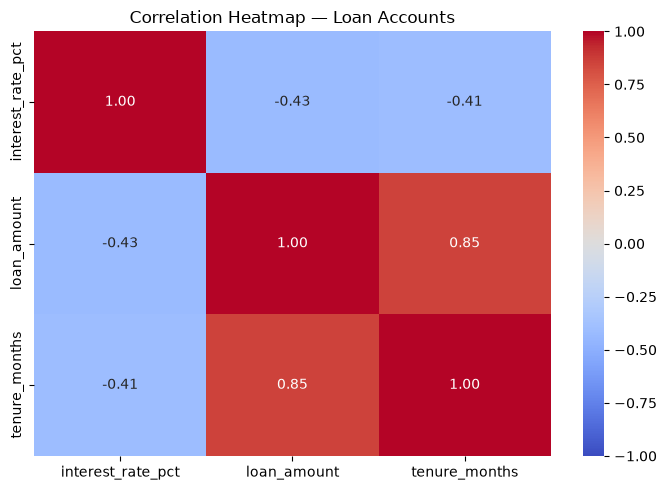

In [31]:
numeric_cols = [
    "interest_rate_pct",
    "loan_amount",
    "tenure_months"
]

corr = loan_acc[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap — Loan Accounts")
plt.tight_layout()
plt.show()

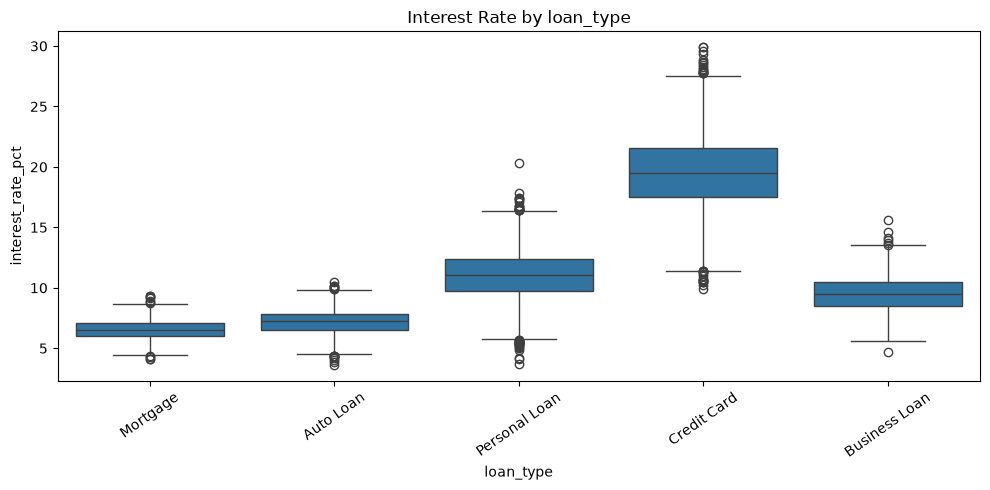

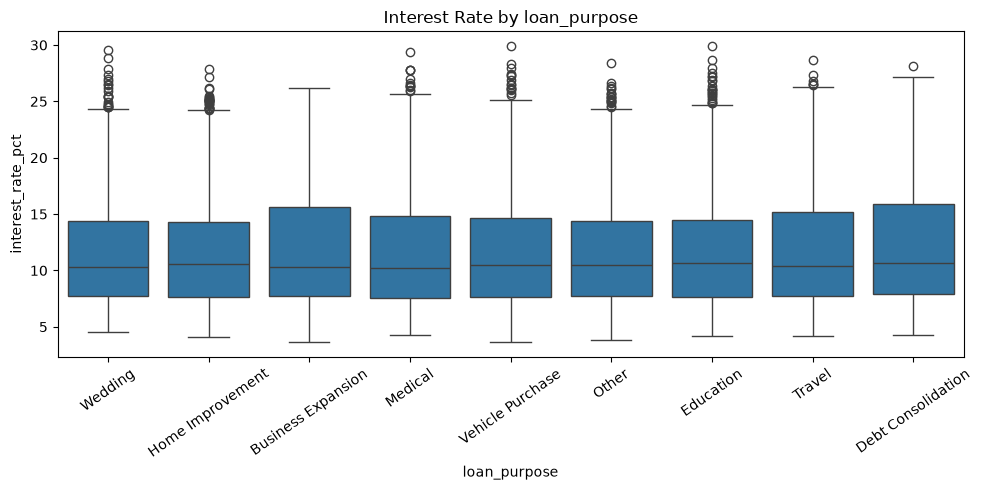

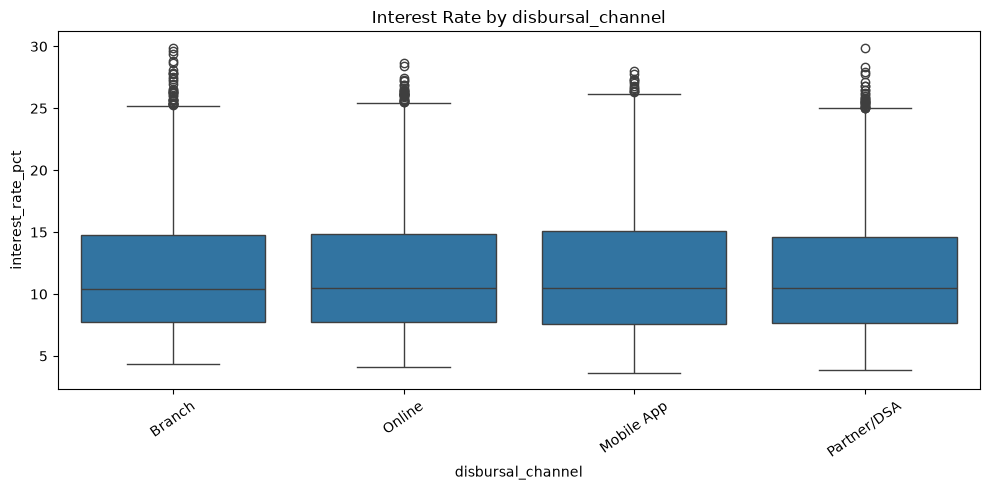

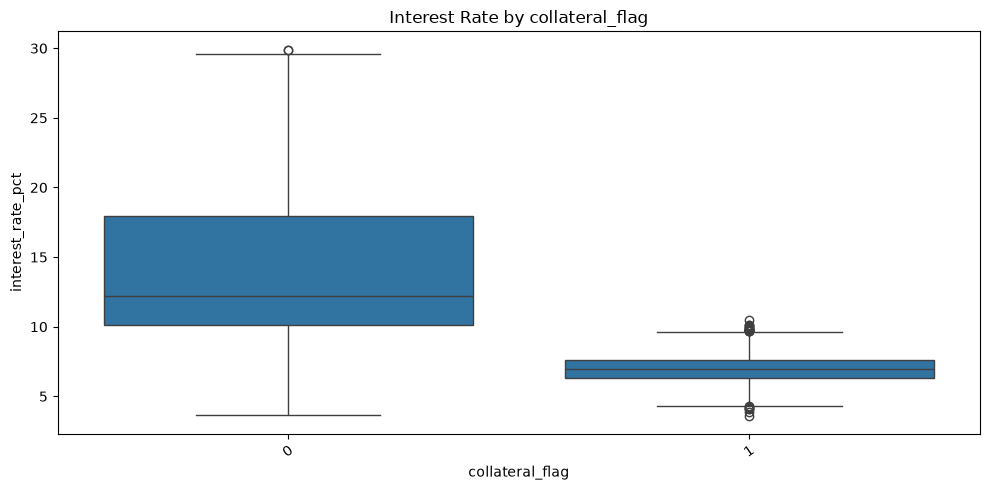

In [32]:
categorical_cols = [
    "loan_type",
    "loan_purpose",
    "disbursal_channel",
    "collateral_flag"
]

for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=loan_acc,
        x=col,
        y="interest_rate_pct"
    )
    plt.title(f"Interest Rate by {col}")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

In [33]:
for col in categorical_cols:
    print(f"\n--- {col} ---")

    summary = loan_acc.groupby(col, dropna=False).agg(
        count=("interest_rate_pct", "count"),
        median=("interest_rate_pct", "median"),
        mean=("interest_rate_pct", "mean")
    )

    print(summary.sort_values("median"))


--- loan_type ---
               count  median       mean
loan_type                              
Mortgage        1399    6.54   6.556497
Auto Loan       2782    7.23   7.198846
Business Loan   1448    9.52   9.502769
Personal Loan   5109   11.09  11.075559
Credit Card     3653   19.53  19.530994

--- loan_purpose ---
                    count  median       mean
loan_purpose                                
Medical              1638  10.235  11.794994
Wedding              1650  10.330  11.730679
Business Expansion   1550  10.340  11.933677
Travel               1616  10.435  11.982840
Other                1537  10.520  11.788868
Vehicle Purchase     1687  10.520  11.820261
Home Improvement     1570  10.535  11.771529
Education            1562  10.630  11.872843
Debt Consolidation   1581  10.690  12.186749

--- disbursal_channel ---
                   count  median       mean
disbursal_channel                          
Branch              3631  10.400  11.890722
Online              3521 

In [34]:
repayment_history.isna().sum()

account_id                    0
payment_month                 0
emi_due                       0
emi_paid                      0
days_past_due                 0
payment_status                0
outstanding_balance           0
origination_date              0
payment_date_reconstructed    0
dtype: int64

In [35]:
duplicate_account_months = repayment_history.duplicated(
    subset=["account_id", "payment_month"],
    keep=False
)

print("Duplicate account-month rows:", duplicate_account_months.sum())

Duplicate account-month rows: 0


In [36]:
#Bureau credit aggregation
bureau_features = (
    bureau_credit.groupby("customer_id")
    .agg(
        # Existing features
        bureau_record_count=("bureau_id", "size"),

        bureau_total=(
            "sanctioned_amount",
            lambda s: s.sum(min_count=1)
        ),

        bureau_total_outstanding=(
            "outstanding_amount",
            lambda s: s.sum(min_count=1)
        ),

        bureau_avg_dpd=("days_past_due", "mean"),
        bureau_max_dpd=("days_past_due", "max"),

        bureau_dpd_missing_count=(
            "days_past_due",
            lambda s: s.isna().sum()
        ),

        bureau_writeoff_count=(
            "account_status",
            lambda s: s.eq("Written-Off").sum()
        ),

        bureau_active_count=(
            "account_status",
            lambda s: s.eq("Active").sum()
        ),

        # New features
        bureau_delinquent_30_count=(
            "days_past_due",
            lambda s: s.ge(30).sum()
        ),
    )
    .reset_index()
)

# Derived features
bureau_features["bureau_active_account_ratio"] = (
    bureau_features["bureau_active_count"]
    / bureau_features["bureau_record_count"].replace(0, np.nan)
)

bureau_features["bureau_outstanding_per_active_account"] = (
    bureau_features["bureau_total_outstanding"]
    / bureau_features["bureau_active_count"].replace(0, np.nan)
)

# Binary indicators
bureau_features["bureau_delinquency_flag"] = (
    bureau_features["bureau_delinquent_30_count"] > 0
).astype(int)


bureau_features["bureau_writeoff_flag"] = (
    bureau_features["bureau_writeoff_count"] > 0
).astype(int)

assert bureau_features["customer_id"].is_unique

bureau_features

,customer_id,bureau_record_count,bureau_total,bureau_total_outstanding,bureau_avg_dpd,bureau_max_dpd,bureau_dpd_missing_count,bureau_writeoff_count,bureau_active_count,bureau_delinquent_30_count,bureau_active_account_ratio,bureau_outstanding_per_active_account,bureau_delinquency_flag,bureau_writeoff_flag
0,CUST100001,3,80472.94,59908.32,39.333333,42.0,0,0,3,3,1.000000,19969.4400,1,0
1,CUST100002,2,73947.83,34998.94,4.000000,8.0,0,0,1,0,0.500000,34998.9400,0,0
2,CUST100003,3,50639.83,18392.44,27.000000,44.0,0,1,1,2,0.333333,18392.4400,1,1
3,CUST100004,2,53678.44,14842.45,12.000000,24.0,0,0,1,0,0.500000,14842.4500,0,0
4,CUST100005,6,115479.54,18908.49,18.000000,49.0,0,0,4,2,0.666667,4727.1225,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8987,CUST109994,2,51059.01,23647.99,14.000000,23.0,0,0,2,0,1.000000,11823.9950,0,0
8988,CUST109995,2,67518.06,15131.08,1.500000,3.0,0,0,1,0,0.500000,15131.0800,0,0
8989,CUST109996,1,7675.32,0.00,0.000000,0.0,0,0,0,0,0.000000,NaN,0,0
8990,CUST109997,3,75280.47,17441.04,7.666667,14.0,0,0,3,0,1.000000,5813.6800,0,0


In [37]:
#Repayment history aggregation
repayment_features = (
    repayment_history.groupby("account_id")
    .agg(
#         repayment_months_observed=("payment_month", "nunique"),

        missed_payment_count=(
            "payment_status",
            lambda s: s.eq("Missed").sum()
        ),
        late_payment_count=(
            "payment_status",
            lambda s: s.eq("Late").sum()
        ),

        repayment_avg_dpd=("days_past_due", "mean"),
        repayment_max_dpd=("days_past_due", "max"),

        total_emi_due=(
            "emi_due",
            lambda s: s.sum(min_count=1)
        ),
        total_emi_paid=(
            "emi_paid",
            lambda s: s.sum(min_count=1)
        )
    )
    .reset_index()
)

assert repayment_features["account_id"].is_unique
repayment_features

,account_id,missed_payment_count,late_payment_count,repayment_avg_dpd,repayment_max_dpd,total_emi_due,total_emi_paid
0,ACC200001,0,4,2.500000,14,22179.84,22179.84
1,ACC200002,1,2,7.000000,45,7779.12,7130.86
2,ACC200003,0,1,2.000000,24,1385.76,1385.76
3,ACC200004,0,1,0.666667,8,7613.28,7613.28
4,ACC200005,0,1,1.750000,21,6391.68,6391.68
...,...,...,...,...,...,...,...
14680,ACC214681,0,1,0.333333,4,10582.92,10582.92
14681,ACC214682,0,0,0.000000,0,7020.12,7020.12
14682,ACC214683,1,1,8.416667,89,4215.24,3863.97
14683,ACC214684,0,3,2.000000,17,7570.68,7570.68


In [38]:
print("Payment month distribution:")
print(repayment_history["payment_month"].value_counts().sort_index())

print("\nUnique payment months per account:")
print(
    repayment_history.groupby("account_id")["payment_month"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("\nMissing payment months:",
      repayment_history["payment_month"].isna().sum())

print("Duplicate account-month records:",
      repayment_history.duplicated(
          subset=["account_id", "payment_month"]
      ).sum())

print("Repayment history rows:", len(repayment_history))
print("Accounts:", repayment_history["account_id"].nunique())


Payment month distribution:
payment_month
1     14685
2     14685
3     14685
4     14685
5     14685
6     14685
7     14685
8     14685
9     14685
10    14685
11    14685
12    14685
Name: count, dtype: int64

Unique payment months per account:
payment_month
12    14685
Name: count, dtype: int64

Missing payment months: 0
Duplicate account-month records: 0
Repayment history rows: 176220
Accounts: 14685


In [39]:
collections_events["event_date"] = pd.to_datetime(
    collections_events["event_date"],
    errors="coerce"
)

#Collection events aggregation
collection_features = (
    collections_events.groupby("account_id")
    .agg(
        collection_event_count=("collection_event_id", "size"),

        payment_received_count=(
            "outcome",
            lambda s: s.eq("Payment Received").sum()
        ),

        event_max_date=("event_date", "max"),

        legal_notice_count=(
            "action_type",
            lambda s: s.eq("Legal Notice").sum()
        ),

        total_amount_recovered=(
            "amount_recovered",
            lambda s: s.sum(min_count=1)
        )
    )
    .reset_index()
)

assert collection_features["account_id"].is_unique
collection_features

,account_id,collection_event_count,payment_received_count,event_max_date,legal_notice_count,total_amount_recovered
0,ACC200002,3,1,2023-06-20,0,0.00
1,ACC200006,1,0,2023-06-22,0,0.00
2,ACC200009,2,0,2021-10-12,0,4068.21
3,ACC200012,3,1,2022-02-19,0,0.00
4,ACC200013,2,1,2021-11-14,1,0.00
...,...,...,...,...,...,...
4273,ACC214671,2,0,2022-04-20,0,5331.91
4274,ACC214672,3,0,2023-11-05,1,0.00
4275,ACC214673,2,0,2019-09-04,0,648.64
4276,ACC214680,2,0,2021-06-23,0,0.00


In [40]:
# Save the original loan-account IDs for validation
original_account_ids = loan_acc["account_id"].copy()
original_row_count = len(loan_acc)

# 1. Join customer attributes
account_data = loan_acc.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator="_customer_join"
)

print("Customer join results:")
print(account_data.isna().sum())
print(account_data["_customer_join"].value_counts())
assert account_data["_customer_join"].eq("both").all()
account_data.drop(columns="_customer_join", inplace=True)


# 2. Join aggregated bureau features
account_data = account_data.merge(
    bureau_features,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator="_bureau_join"
)

print("Bureau join results:")
print(account_data["_bureau_join"].value_counts())
account_data.drop(columns="_bureau_join", inplace=True)
# 3. Join aggregated repayment features

account_data = account_data.merge(
    repayment_features,
    on="account_id",
    how="left",
    validate="one_to_one",
    indicator="_repayment_join"
)

print("Repayment join results:")
print(account_data["_repayment_join"].value_counts())
account_data.drop(columns="_repayment_join", inplace=True)

# 4. Join aggregated collections features

account_data = account_data.merge(
    collection_features,
    on="account_id",
    how="left",
    validate="one_to_one",
    indicator="_collections_join"
)

print("Collections join results:")
print(account_data["_collections_join"].value_counts())
account_data.drop(columns="_collections_join", inplace=True)


# Verify no account duplication or row loss
assert len(account_data) == original_row_count
assert account_data["account_id"].is_unique
assert set(account_data["account_id"]) == set(original_account_ids)

print("Original loan rows:", original_row_count)
print("Final account rows:", len(account_data))
print("Unique accounts:", account_data["account_id"].nunique())
print("Final shape:", account_data.shape)

Customer join results:
account_id              0
customer_id             0
loan_type               0
loan_purpose            0
loan_amount             0
interest_rate_pct     294
tenure_months           0
origination_date        0
disbursal_channel       0
collateral_flag         0
target_default          0
age                     0
gender                  0
marital_status          0
education_level         0
employment_type         0
occupation_sector       0
years_employed        688
annual_income           0
region                  0
city_tier               0
num_dependents        716
housing_type            0
years_at_residence    717
customer_since          0
residence_missing       0
_customer_join          0
dtype: int64
_customer_join
both          14685
left_only         0
right_only        0
Name: count, dtype: int64
Bureau join results:
_bureau_join
both          13223
left_only      1462
right_only        0
Name: count, dtype: int64
Repayment join results:
_repayment_join
b

C:\Users\ESHIKA\AppData\Local\Temp\ipykernel_27060\2407691679.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  account_data.drop(columns="_customer_join", inplace=True)
C:\Users\ESHIKA\AppData\Local\Temp\ipykernel_27060\2407691679.py:32: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  account_data.drop(columns="_bureau_join", inplace=True)
C:\Users\ESHIKA\AppData\Local\Temp\ipykernel_27060\2407691679.py:45: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  account_data.drop(columns

In [41]:
account_data.isna().sum()

account_id                                   0
customer_id                                  0
loan_type                                    0
loan_purpose                                 0
loan_amount                                  0
interest_rate_pct                          294
tenure_months                                0
origination_date                             0
disbursal_channel                            0
collateral_flag                              0
target_default                               0
age                                          0
gender                                       0
marital_status                               0
education_level                              0
employment_type                              0
occupation_sector                            0
years_employed                             688
annual_income                                0
region                                       0
city_tier                                    0
num_dependent

In [42]:
account_data.loc[
    account_data["bureau_record_count"].isna(),
    "bureau_outstanding_per_active_account"
].value_counts(dropna=False)

bureau_outstanding_per_active_account
NaN    1462
Name: count, dtype: int64

In [43]:
# 1. Identify customers with no bureau records
account_data["bureau_no_record_flag"] = (
    account_data["bureau_record_count"].isna()
).astype("int8")

# 2. Identify customers with no active bureau accounts
account_data["bureau_no_active_account_flag"] = (
    account_data["bureau_active_count"].fillna(0).eq(0)
).astype("int8")

In [44]:
account_data.bureau_no_active_account_flag.value_counts()

bureau_no_active_account_flag
0    9876
1    4809
Name: count, dtype: int64

In [45]:
cols_to_fill = [
    "bureau_record_count",
    "bureau_total",
    "bureau_total_outstanding",
    "bureau_dpd_missing_count",
    "bureau_writeoff_count",
    "bureau_active_count",
    "bureau_delinquent_30_count",
    "bureau_delinquency_flag",
    "bureau_writeoff_flag",
    "bureau_active_account_ratio",
    "bureau_outstanding_per_active_account",
    "bureau_avg_dpd",
    "bureau_max_dpd",
]

mask = account_data["bureau_no_record_flag"].eq(1)

account_data.loc[mask, cols_to_fill] = (
    account_data.loc[mask, cols_to_fill].fillna(0)
)

In [46]:
account_data.isna().sum()

account_id                                   0
customer_id                                  0
loan_type                                    0
loan_purpose                                 0
loan_amount                                  0
interest_rate_pct                          294
tenure_months                                0
origination_date                             0
disbursal_channel                            0
collateral_flag                              0
target_default                               0
age                                          0
gender                                       0
marital_status                               0
education_level                              0
employment_type                              0
occupation_sector                            0
years_employed                             688
annual_income                                0
region                                       0
city_tier                                    0
num_dependent

In [47]:
account_data.loc[
    account_data["bureau_outstanding_per_active_account"].isna(),
    "bureau_no_active_account_flag"
].value_counts(dropna=False)

bureau_no_active_account_flag
1    3347
Name: count, dtype: int64

In [48]:
cols = [
    "years_employed",
    "num_dependents",
    "years_at_residence"
]

print("Original customer-level missing counts:")
print(customers[cols].isna().sum())

print("\nUnique customers with missing values in account_data:")
print(
    account_data.groupby("customer_id")[cols]
    .first()
    .isna()
    .sum()
)

print("\nCurrent missingness flags:")
print(
    account_data[
        [
            "residence_missing"
        ]
    ].sum()
)

Original customer-level missing counts:
years_employed        477
num_dependents        500
years_at_residence    500
dtype: int64

Unique customers with missing values in account_data:
years_employed        477
num_dependents        500
years_at_residence    500
dtype: int64

Current missingness flags:
residence_missing    717
dtype: int64


In [50]:
repayment_feature_rows = []

for account_id, group in repayment_history.groupby("account_id"):

    # Sort chronologically
    group = group.sort_values("payment_month").copy()

    status = group["payment_status"].astype(str).str.strip().str.lower()

    # Identify missed payments
    group["is_missed"] = status.eq("missed").astype(int)

    # 1. Missed payments in the latest 3 recorded months
    missed_last3 = group["is_missed"].tail(3).sum()

    # 2. Longest consecutive missed-payment streak
    missed = group["is_missed"].to_numpy()

    longest_streak = 0
    current_streak = 0

    for value in missed:
        if value == 1:
            current_streak += 1
            longest_streak = max(longest_streak, current_streak)
        else:
            current_streak = 0

    # 3. DPD trend: latest 6 months minus first 6 months
    dpd = pd.to_numeric(
        group["days_past_due"], errors="coerce"
    )

    if group["payment_month"].nunique() >= 12:
        first_six_dpd = dpd.head(6).mean()
        last_six_dpd = dpd.tail(6).mean()

        dpd_trend = last_six_dpd - first_six_dpd
    else:
        dpd_trend = np.nan

    repayment_feature_rows.append({
        "account_id": account_id,
        "missed_last3": missed_last3,
        "longest_missed_streak": longest_streak,
        "dpd_trend": dpd_trend
    })


new_repayment_features = pd.DataFrame(repayment_feature_rows)

assert new_repayment_features["account_id"].is_unique

display(new_repayment_features.head())
print("Shape:", new_repayment_features.shape)
print("\nMissing values:")
print(new_repayment_features.isna().sum())

,account_id,missed_last3,longest_missed_streak,dpd_trend
0,ACC200001,0,0,-4.333333
1,ACC200002,0,1,-4.666667
2,ACC200003,0,0,-4.000000
3,ACC200004,0,0,-1.333333
4,ACC200005,0,0,3.500000


Shape: (14685, 4)

Missing values:
account_id               0
missed_last3             0
longest_missed_streak    0
dpd_trend                0
dtype: int64


In [51]:
bureau_utilisation = (
    bureau_credit.groupby("customer_id")
    .agg(
        bureau_total_sanctioned=(
            "sanctioned_amount",
            lambda s: s.sum(min_count=1)
        ),
        bureau_total_outstanding=(
            "outstanding_amount",
            lambda s: s.sum(min_count=1)
        )
    )
    .reset_index()
)

# Calculate utilisation safely
bureau_utilisation["bureau_utilisation"] = (
    bureau_utilisation["bureau_total_outstanding"]
    / bureau_utilisation["bureau_total_sanctioned"].replace(0, np.nan)
)

bureau_utilisation["bureau_utilisation"] = (
    bureau_utilisation["bureau_utilisation"]
    .replace([np.inf, -np.inf], np.nan)
)

assert bureau_utilisation["customer_id"].is_unique

display(bureau_utilisation.head())

print("Missing bureau utilisation:",
      bureau_utilisation["bureau_utilisation"].isna().sum())

print("\nSummary:")
display(bureau_utilisation["bureau_utilisation"].describe())

,customer_id,bureau_total_sanctioned,bureau_total_outstanding,bureau_utilisation
0,CUST100001,80472.94,59908.32,0.744453
1,CUST100002,73947.83,34998.94,0.473292
2,CUST100003,50639.83,18392.44,0.363201
3,CUST100004,53678.44,14842.45,0.276507
4,CUST100005,115479.54,18908.49,0.163739


Missing bureau utilisation: 0

Summary:


count    8992.000000
mean        0.356468
std         0.259330
min         0.000000
25%         0.139803
50%         0.343298
75%         0.545520
max         0.999226
Name: bureau_utilisation, dtype: float64

In [52]:
# Remove old copies if rerunning
account_data = account_data.drop(
    columns=[
        "missed_last3",
        "longest_missed_streak",
        "dpd_trend",
        "bureau_utilisation"
    ],
    errors="ignore"
)

# Merge repayment features at account level
account_data = account_data.merge(
    new_repayment_features,
    on="account_id",
    how="left",
    validate="one_to_one"
)

# Merge bureau utilisation at customer level
account_data = account_data.merge(
    bureau_utilisation[["customer_id", "bureau_utilisation"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

assert account_data["account_id"].is_unique

new_features = [
    "missed_last3",
    "longest_missed_streak",
    "dpd_trend",
    "bureau_utilisation"
]

print("New feature summary:")
display(account_data[new_features].describe().T)

print("\nMissing values:")
print(account_data[new_features].isna().sum())

New feature summary:


,count,mean,std,min,25%,50%,75%,max
missed_last3,14685.0,0.139734,0.371013,0.000000,0.000000,0.000000,0.000000,3.000000
longest_missed_streak,14685.0,0.446510,0.559290,0.000000,0.000000,0.000000,1.000000,4.000000
dpd_trend,14685.0,0.086233,7.924851,-36.666667,-3.666667,0.000000,3.833333,47.333333
bureau_utilisation,13223.0,0.357260,0.260589,0.000000,0.138142,0.343526,0.549359,0.999226



Missing values:
missed_last3                0
longest_missed_streak       0
dpd_trend                   0
bureau_utilisation       1462
dtype: int64


In [53]:
no_bureau = account_data["bureau_record_count"].isna()

print("No bureau records:", no_bureau.sum())

print(
    "Missing bureau total among accounts WITH bureau records:",
    account_data.loc[~no_bureau, "bureau_total"].isna().sum()
)

print(
    "Missing bureau outstanding among accounts WITH bureau records:",
    account_data.loc[
        ~no_bureau, "bureau_total_outstanding"
    ].isna().sum()
)

No bureau records: 0
Missing bureau total among accounts WITH bureau records: 0
Missing bureau outstanding among accounts WITH bureau records: 0


In [54]:
no_collections = account_data["collection_event_count"].isna()
has_collections = ~no_collections

print(
    "Missing recovered amount among accounts with collections:",
    account_data.loc[
        has_collections, "total_amount_recovered"
    ].isna().sum()
)

Missing recovered amount among accounts with collections: 0


In [55]:
collection_zero_cols = [
    "collection_event_count",
    "payment_received_count",
    "legal_notice_count",
    "total_amount_recovered",
]

no_events = account_data["collection_event_count"].isna()

account_data.loc[no_events, collection_zero_cols] = (
    account_data.loc[no_events, collection_zero_cols].fillna(0)
)

account_data["no_collection_events"] = no_events.astype("int8")

In [56]:
account_data.isna().sum()

account_id                                   0
customer_id                                  0
loan_type                                    0
loan_purpose                                 0
loan_amount                                  0
interest_rate_pct                          294
tenure_months                                0
origination_date                             0
disbursal_channel                            0
collateral_flag                              0
target_default                               0
age                                          0
gender                                       0
marital_status                               0
education_level                              0
employment_type                              0
occupation_sector                            0
years_employed                             688
annual_income                                0
region                                       0
city_tier                                    0
num_dependent

In [57]:
# Validate account-level grain
assert len(account_data) == original_row_count
assert account_data["account_id"].is_unique
assert set(account_data["account_id"]) == set(original_account_ids)

print("Final rows:", len(account_data))
print("Unique accounts:", account_data["account_id"].nunique())
print("Final shape:", account_data.shape)

Final rows: 14685
Unique accounts: 14685
Final shape: (14685, 57)


In [58]:
# Work on a copy
account_data = account_data.copy()

# Helper: avoid division by zero
def safe_divide(numerator, denominator):
    denominator = denominator.replace(0, np.nan)
    return numerator / denominator

# 1. EMI payment ratio
account_data["emi_payment_ratio"] = safe_divide(
    account_data["total_emi_paid"],
    account_data["total_emi_due"]
)


# 2. Loan amount relative to annual income
account_data["loan_to_income_ratio"] = safe_divide(
    account_data["loan_amount"],
    account_data["annual_income"]
)

# 3. Bureau outstanding relative to annual income
account_data["bureau_outstanding_ratio"] = safe_divide(
    account_data["bureau_total_outstanding"],
    account_data["annual_income"]
)
# 4. Difference between repayment and bureau average DPD
account_data["dpd_gap"] = (
    account_data["repayment_avg_dpd"]
    - account_data["bureau_avg_dpd"]
)

# Convert any infinite values to missing
new_features = [
    "emi_payment_ratio",
    "loan_to_income_ratio",
    "bureau_outstanding_ratio",
    "dpd_gap"
]

account_data[new_features] = (
    account_data[new_features]
    .replace([np.inf, -np.inf], np.nan)
)

# Inspect the new features
print(account_data[new_features].describe().round(3))
print("\nMissing values:")
print(account_data[new_features].isna().sum())

       emi_payment_ratio  loan_to_income_ratio  bureau_outstanding_ratio  \
count          14685.000             14685.000                 14685.000   
mean               0.953                 0.607                     0.251   
std                0.065                 1.157                     0.356   
min                0.500                 0.007                     0.000   
25%                0.917                 0.120                     0.004   
50%                1.000                 0.229                     0.151   
75%                1.000                 0.473                     0.350   
max                1.000                25.534                     7.883   

         dpd_gap  
count  14548.000  
mean      -8.102  
std       12.584  
min      -65.667  
25%      -15.750  
50%       -6.167  
75%        1.250  
max       30.083  

Missing values:
emi_payment_ratio             0
loan_to_income_ratio          0
bureau_outstanding_ratio      0
dpd_gap                     137

In [59]:
print(
    account_data[new_features]
    .quantile([0, 0.25, 0.50, 0.75, 0.95, 0.99, 1])
    .round(3)
)

      emi_payment_ratio  loan_to_income_ratio  bureau_outstanding_ratio  \
0.00              0.500                 0.007                     0.000   
0.25              0.917                 0.120                     0.004   
0.50              1.000                 0.229                     0.151   
0.75              1.000                 0.473                     0.350   
0.95              1.000                 2.843                     0.840   
0.99              1.000                 5.212                     1.580   
1.00              1.000                25.534                     7.883   

      dpd_gap  
0.00  -65.667  
0.25  -15.750  
0.50   -6.167  
0.75    1.250  
0.95    8.417  
0.99   14.044  
1.00   30.083  


In [60]:
# Customers whose bureau aggregates are missing
missing_bureau = account_data.loc[
    account_data["bureau_record_count"].isna(),
    ["account_id", "customer_id"]
].copy()

# Count matching bureau records for each affected customer
bureau_counts = (
    bureau_credit.groupby("customer_id")
    .size()
    .rename("actual_bureau_records")
)

missing_bureau = missing_bureau.join(
    bureau_counts,
    on="customer_id"
)

# No matching records means the count will be NaN after the join
missing_bureau["actual_bureau_records"] = (
    missing_bureau["actual_bureau_records"].fillna(0)
)

print("Accounts with missing bureau aggregates:", len(missing_bureau))
print("\nActual bureau record counts:")
print(missing_bureau["actual_bureau_records"].value_counts().sort_index())

print("\nSample:")
print(missing_bureau.head(10))

Accounts with missing bureau aggregates: 0

Actual bureau record counts:
Series([], Name: count, dtype: int64)

Sample:
Empty DataFrame
Columns: [account_id, customer_id, actual_bureau_records]
Index: []


In [61]:
# Accounts whose collections aggregates are missing
missing_collections = account_data.loc[
    account_data["collection_event_count"].isna(),
    ["account_id"]
].copy()

# Count actual collection events for each account
collection_counts = (
    collections_events.groupby("account_id")
    .size()
    .rename("actual_collection_events")
)

missing_collections = missing_collections.join(
    collection_counts,
    on="account_id"
)

missing_collections["actual_collection_events"] = (
    missing_collections["actual_collection_events"].fillna(0)
)

print(
    "Accounts with missing collections aggregates:",
    len(missing_collections)
)

print("\nActual collection event counts:")
print(
    missing_collections["actual_collection_events"]
    .value_counts()
    .sort_index()
)

print("\nSample:")
print(missing_collections.head(10))

Accounts with missing collections aggregates: 0

Actual collection event counts:
Series([], Name: count, dtype: int64)

Sample:
Empty DataFrame
Columns: [account_id, actual_collection_events]
Index: []


In [75]:
account_data = account_data.copy()

# Calculate monthly interest rate
monthly_rate = (
    account_data["interest_rate_pct"] / 100 / 12
)

principal = account_data["loan_amount"]
tenure = account_data["tenure_months"]

# Calculate estimated monthly EMI
estimated_emi = np.where(
    monthly_rate > 0,
    principal * (
        monthly_rate * (1 + monthly_rate) ** tenure
    ) / (
        (1 + monthly_rate) ** tenure - 1
    ),
    principal / tenure
)

# Add the new affordability feature
account_data["emi_to_income_ratio"] = (
    estimated_emi / (account_data["annual_income"] / 12)
)

account_data["emi_to_income_ratio"] = (
    account_data["emi_to_income_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

print("New feature added.")
print("Feature count:", len(account_data.columns))

New feature added.
Feature count: 64


Data Analytics

In [62]:
def profile_segment(df, group_cols):
    # Keep rows with valid binary targets
    valid = df.loc[
        df["target_default"].isin([0, 1])
    ].copy()

    if valid.empty:
        raise ValueError("No records with valid binary targets.")

    # Each account should occur only once in account-level data
    if valid["account_id"].duplicated().any():
        raise ValueError(
            "Duplicate account_id values found. "
            "Resolve duplicates before profiling."
        )

    result = (
        valid.groupby(group_cols, dropna=False)
        .agg(
            accounts=("account_id", "nunique"),
            customers=("customer_id", "nunique"),
            exposure=("loan_amount", lambda s: s.sum(min_count=1)),
            defaulted_accounts=("target_default", "sum"),
            avg_loan_amount=("loan_amount", "mean"),
        )
        .reset_index()
    )

    # Exposure share is based on non-missing loan amounts
    total_exposure = valid["loan_amount"].sum(min_count=1)

    if pd.notna(total_exposure) and total_exposure != 0:
        result["exposure_share_pct"] = (
            result["exposure"] / total_exposure * 100
        )
    else:
        result["exposure_share_pct"] = np.nan

    result["default_rate_pct"] = (
        result["defaulted_accounts"] / result["accounts"] * 100
    )

    return result.sort_values(
        "exposure_share_pct",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)


In [63]:

valid = account_data.loc[
    account_data["target_default"].isin([0, 1])
].copy()

# 1. Validate account-level grain
assert valid["account_id"].is_unique, (
    "Duplicate account IDs found."
)

# 2. Validate binary target
assert valid["target_default"].isin([0, 1]).all()

print("Eligible accounts:", len(valid))
print("Unique accounts:", valid["account_id"].nunique())
print("Unique customers:", valid["customer_id"].nunique())
print("Total original loan amount:", valid["loan_amount"].sum())
print(
    "Overall account default rate:",
    round(valid["target_default"].mean() * 100, 2), "%"
)

# 3. Segment-level profiling
loan_type_profile = profile_segment(valid, ["loan_type"])

print("\nLoan type exposure shares and default rates:")
print(
    loan_type_profile[
        [
            "loan_type",
            "accounts",
            "exposure",
            "exposure_share_pct",
            "default_rate_pct",
        ]
    ].round(2).to_string(index=False)
)

print(
    "\nSum of loan type exposure shares:",
    round(loan_type_profile["exposure_share_pct"].sum(), 4)
)


Eligible accounts: 14685
Unique accounts: 14685
Unique customers: 10000
Total original loan amount: 601119531.64
Overall account default rate: 16.1 %

Loan type exposure shares and default rates:
    loan_type  accounts     exposure  exposure_share_pct  default_rate_pct
     Mortgage      1432 314473751.28               52.31             24.65
Business Loan      1484  99017631.21               16.47             16.04
Personal Loan      5216  78815492.74               13.11             14.90
    Auto Loan      2832  78795814.42               13.11             13.88
  Credit Card      3721  30016841.99                4.99             16.21

Sum of loan type exposure shares: 100.0


In [64]:
amount = account_data["loan_amount"]

print("Rows:", len(account_data))
print("Unique accounts:", account_data["account_id"].nunique())
print("Duplicate account IDs:", account_data["account_id"].duplicated().sum())

print("\nMissing loan amounts:", amount.isna().sum())
print("Infinite loan amounts:", np.isinf(amount).sum())
print("Zero loan amounts:", amount.eq(0).sum())
print("Negative loan amounts:", amount.lt(0).sum())

# Summary of finite loan amounts
finite_amount = amount[amount.notna() & np.isfinite(amount)]

print("\nLoan amount summary:")
print(
    finite_amount.describe(
        percentiles=[.01, .25, .50, .75, .95, .99]
    ).round(2)
)


Rows: 14685
Unique accounts: 14685
Duplicate account IDs: 0

Missing loan amounts: 0
Infinite loan amounts: 0
Zero loan amounts: 0
Negative loan amounts: 0

Loan amount summary:
count     14685.00
mean      40934.25
std       64872.14
min        1000.00
1%         1000.00
25%        9578.36
50%       17334.01
75%       31947.74
95%      218034.24
99%      295203.79
max      444803.02
Name: loan_amount, dtype: float64


In [65]:
# Valid binary targets
valid_target = account_data["target_default"].isin([0, 1])

# Valid exposure amounts
valid_amount = (
    account_data["loan_amount"].notna()
    & np.isfinite(account_data["loan_amount"])
    & account_data["loan_amount"].ge(0)
)

# Default-rate population
default_data = account_data.loc[valid_target].copy()

# Exposure population
exposure_data = account_data.loc[
    valid_target & valid_amount
].copy()

print("Accounts with valid targets:", len(default_data))
print("Accounts with valid targets and amounts:", len(exposure_data))
print("Accounts excluded from exposure:", len(default_data) - len(exposure_data))

print("Total original exposure:", exposure_data["loan_amount"].sum())
print("Overall default rate (%):",
      default_data["target_default"].mean() * 100)

Accounts with valid targets: 14685
Accounts with valid targets and amounts: 14685
Accounts excluded from exposure: 0
Total original exposure: 601119531.64
Overall default rate (%): 16.09805924412666


In [66]:

def build_segment_summary(df, group_cols):
    valid_targets = df.loc[
        df["target_default"].isin([0, 1])
    ].copy()

    if valid_targets.empty:
        raise ValueError("No records with valid binary targets.")

    if valid_targets["account_id"].duplicated().any():
        raise ValueError("Duplicate account IDs found.")

    valid_exposure = valid_targets.loc[
        valid_targets["loan_amount"].notna()
        & np.isfinite(valid_targets["loan_amount"])
        & valid_targets["loan_amount"].ge(0)
    ].copy()

    default_summary = (
        valid_targets.groupby(
            group_cols, dropna=False, observed=True
        )
        .agg(
            accounts=("account_id", "nunique"),
            customers=("customer_id", "nunique"),
            defaulted_accounts=("target_default", "sum"),
            default_rate_pct=("target_default",
                              lambda s: s.mean() * 100)
        )
        .reset_index()
    )

    exposure_summary = (
        valid_exposure.groupby(
            group_cols, dropna=False, observed=True
        )
        .agg(exposure=("loan_amount", "sum"))
        .reset_index()
    )

    total_exposure = valid_exposure["loan_amount"].sum()

    if total_exposure > 0:
        exposure_summary["exposure_share_pct"] = (
            exposure_summary["exposure"] / total_exposure * 100
        )
    else:
        exposure_summary["exposure_share_pct"] = np.nan

    result = default_summary.merge(
        exposure_summary,
        on=group_cols,
        how="left",
        validate="one_to_one"
    )

    overall_default_rate = valid_targets["target_default"].mean() * 100

    result["default_rate_diff_pp"] = (
        result["default_rate_pct"] - overall_default_rate
    )

    return result.sort_values(
        "exposure_share_pct",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)


In [67]:
# income_profile = profile_segment(account_data, ["income_band"])
# print(income_profile.round(2))

account_data["income_band"] = pd.cut(
    account_data["annual_income"],
    bins=[-np.inf, 25_000, 50_000, 75_000, 100_000, np.inf],
    labels=[
        "Below $25k",
        "$25k–$50k",
        "$50k–$75k",
        "$75k–$100k",
        "$100k+"
    ],
    right=False
)

In [68]:
# Age bands

account_data["age_band"] = pd.cut(
    account_data["age"],
    bins=[-np.inf, 25, 35, 45, 55, 65, np.inf],
    labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"],
    right=False
)


In [69]:
segment_summaries = {
    "income": build_segment_summary(account_data, ["income_band"]),
    "employment": build_segment_summary(account_data, ["employment_type"]),
    "region": build_segment_summary(account_data, ["region"]),
    "age": build_segment_summary(account_data, ["age_band"]),
    "loan_type": build_segment_summary(account_data, ["loan_type"]),
}

for name, summary in segment_summaries.items():
    print(f"\n{name.upper()} PROFILE")
    print(summary.round(2).to_string(index=False))


INCOME PROFILE
income_band  accounts  customers  defaulted_accounts  default_rate_pct     exposure  exposure_share_pct  default_rate_diff_pp
 $75k–$100k      5281       3593                 722             13.67 215815663.83               35.90                 -2.43
  $50k–$75k      4466       3036                 833             18.65 184226287.59               30.65                  2.55
     $100k+      3098       2127                 295              9.52 124466502.00               20.71                 -6.58
  $25k–$50k      1519       1018                 387             25.48  64348554.36               10.70                  9.38
 Below $25k       321        226                 127             39.56  12262523.86                2.04                 23.47

EMPLOYMENT PROFILE
employment_type  accounts  customers  defaulted_accounts  default_rate_pct     exposure  exposure_share_pct  default_rate_diff_pp
       Salaried      7546       5149                1130             14.97 313

In [70]:
# Recreate default_data AFTER income_band has been created
default_data = account_data.loc[
    account_data["target_default"].isin([0, 1])
].copy()

# Verify the required column exists
assert "income_band" in default_data.columns, (
    "income_band is missing from default_data"
)

cross_tab = (
    default_data
    .groupby(
        ["income_band", "employment_type"],
        observed=False,
        dropna=False
    )
    .agg(
        accounts=("account_id", "nunique"),
        customers=("customer_id", "nunique"),
        defaulted_accounts=("target_default", "sum"),
        default_rate=("target_default", "mean")
    )
    .reset_index()
)

cross_tab["default_rate_pct"] = cross_tab["default_rate"] * 100

cross_tab["sample_flag"] = np.where(
    cross_tab["accounts"] < 30,
    "Small sample",
    "Sufficient for descriptive reporting"
)

print(
    cross_tab[
        [
            "income_band",
            "employment_type",
            "accounts",
            "defaulted_accounts",
            "default_rate_pct",
            "sample_flag"
        ]
    ].to_string(index=False)
)

income_band employment_type  accounts  defaulted_accounts  default_rate_pct                          sample_flag
 Below $25k  Business Owner         6                   2         33.333333                         Small sample
 Below $25k        Contract        29                  12         41.379310                         Small sample
 Below $25k        Salaried        58                  15         25.862069 Sufficient for descriptive reporting
 Below $25k   Self-Employed        33                  11         33.333333 Sufficient for descriptive reporting
 Below $25k      Unemployed       195                  87         44.615385 Sufficient for descriptive reporting
  $25k–$50k  Business Owner        77                  15         19.480519 Sufficient for descriptive reporting
  $25k–$50k        Contract       232                  65         28.017241 Sufficient for descriptive reporting
  $25k–$50k        Salaried       648                 142         21.913580 Sufficient for descr

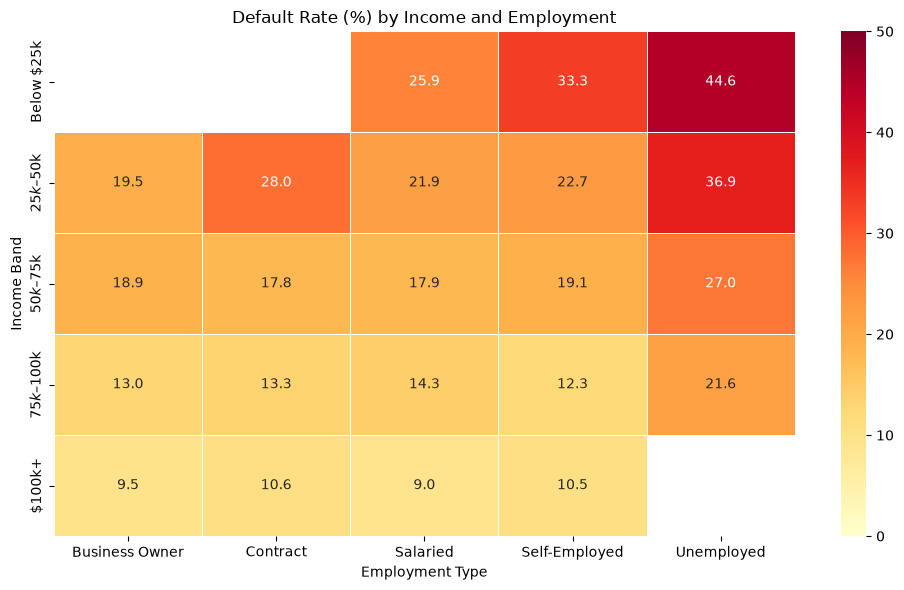

In [71]:
# Create a pivot table for default rates
rate_matrix = cross_tab.pivot(
    index="income_band",
    columns="employment_type",
    values="default_rate_pct"
)

# Create a matching matrix of sample sizes
count_matrix = cross_tab.pivot(
    index="income_band",
    columns="employment_type",
    values="accounts"
)

# Hide rates where fewer than 30 accounts exist
display_matrix = rate_matrix.where(count_matrix >= 30)


plt.figure(figsize=(10, 6))

sns.heatmap(
    display_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=50,
    mask=display_matrix.isna(),
    linewidths=0.5
)

plt.title("Default Rate (%) by Income and Employment")
plt.xlabel("Employment Type")
plt.ylabel("Income Band")
plt.tight_layout()
plt.show()

# Credit Risk Portfolio Analytics: Key Findings and Business Implications

### 1. Mortgage Loans Represent the Largest Exposure and Highest Default Risk
Mortgages account for **52.31% of total original loan exposure ($314.47M)** and have a default rate of **24.65%**, compared with the portfolio average of 16.10%. This combination of high exposure concentration and elevated default incidence makes mortgages the most significant segment to monitor.

**Business implication:** Prioritize mortgage portfolio reviews, focusing on underwriting quality, borrower affordability and repayment performance to identify opportunities for risk mitigation.

### 2. Default Rates Decline as Borrower Income Increases
Borrowers earning below $25,000 annually have a default rate of **39.56%**, compared with 9.52% among borrowers earning $100,000 or more. The lowest-income segment's default rate is approximately 2.46 times the overall portfolio average.

**Business implication:** Strengthen affordability assessments by considering income alongside existing obligations and repayment capacity. Use these findings to identify segments that may benefit from closer monitoring.

### 3. Unemployed Borrowers Exhibit Elevated Default Risk
The unemployed segment has a default rate of **34.96% across 718 accounts**, compared with 14.97% for salaried borrowers and 15.33% for self-employed borrowers. This is 18.86 percentage points above the overall portfolio default rate.

**Business implication:** Examine income stability, repayment capacity and other risk indicators when assessing this segment. Employment status should be considered alongside other relevant factors rather than used as a standalone decision criterion.

### 4. Younger Borrowers Have Higher Observed Default Rates
Borrowers under 25 have a default rate of **22.39%**, while those aged 45–54 have a rate of 12.11%. The 25–34 age group also records an above-average default rate of 18.75%. The rate among borrowers aged 65 and above is only 4.03%, although this segment contains 124 accounts.

**Business implication:** Investigate whether differences in income stability, credit history, affordability or loan characteristics help explain the higher default rates among younger borrowers. Interpret smaller age segments cautiously.

### 5. Combining Income and Employment Reveals Higher-Risk Segments
The cross-dimensional analysis shows a **44.62% default rate among unemployed borrowers earning below $25,000**, across 195 accounts. By comparison, salaried borrowers in the same income band have a default rate of 25.86% across 58 accounts.

**Business implication:** Combining borrower characteristics provides a more nuanced view of portfolio risk than examining each dimension independently. Use such segments to guide further investigation and targeted monitoring, while validating findings against other borrower and loan characteristics.

### 6. Regional Default Rates Are Relatively Consistent
Regional default rates range from **15.00% in Central to 16.86% in the South**, a difference of just 1.86 percentage points. All five regions have default rates relatively close to the overall portfolio average of 16.10%.

**Business implication:** Region appears less differentiating than income, employment and loan type in this descriptive analysis. Further analysis should examine regional results alongside loan mix and borrower characteristics before prioritizing geography-specific interventions.

### Overall Conclusion
The portfolio's observed default risk is most pronounced in the mortgage segment and among lower-income and unemployed borrowers. Combining income and employment provides additional insight into higher-risk segments, while regional differences are comparatively modest. These findings can guide portfolio monitoring and further investigation, but they represent descriptive associations rather than evidence of causation or guaranteed predictors of future defaults.

*Note: Exposure refers to original loan amounts, not current outstanding balances or realized losses. Findings describe the supplied default labels and should be interpreted in light of segment sizes and the dataset's limitations.*

# Default model

In [72]:
account_data.columns

Index(['account_id', 'customer_id', 'loan_type', 'loan_purpose', 'loan_amount',
       'interest_rate_pct', 'tenure_months', 'origination_date',
       'disbursal_channel', 'collateral_flag', 'target_default', 'age',
       'gender', 'marital_status', 'education_level', 'employment_type',
       'occupation_sector', 'years_employed', 'annual_income', 'region',
       'city_tier', 'num_dependents', 'housing_type', 'years_at_residence',
       'customer_since', 'residence_missing', 'bureau_record_count',
       'bureau_total', 'bureau_total_outstanding', 'bureau_avg_dpd',
       'bureau_max_dpd', 'bureau_dpd_missing_count', 'bureau_writeoff_count',
       'bureau_active_count', 'bureau_delinquent_30_count',
       'bureau_active_account_ratio', 'bureau_outstanding_per_active_account',
       'bureau_delinquency_flag', 'bureau_writeoff_flag',
       'missed_payment_count', 'late_payment_count', 'repayment_avg_dpd',
       'repayment_max_dpd', 'total_emi_due', 'total_emi_paid',
       'col

In [76]:
account_data["customer_since"] = pd.to_datetime(
account_data["customer_since"],
errors="coerce")

In [77]:
def oversample_minority(y):
    minority_count = int((np.asarray(y) == 1).sum())
    target_count = int(np.ceil(minority_count * 1.2))

    return {1: target_count}

In [78]:
# Loan-type-wise default rate and account count
loan_type_summary = (
    account_data
    .groupby("loan_type", dropna=False)
    .agg(
        total_accounts=("target_default", "size"),
        defaults=("target_default", "sum"),
        default_rate=("target_default", "mean")
    )
    .reset_index()
)

loan_type_summary["default_rate_pct"] = (
    loan_type_summary["default_rate"] * 100
).round(2)

loan_type_summary = loan_type_summary.sort_values(
    "default_rate_pct", ascending=False
)

display(
    loan_type_summary[
        ["loan_type", "total_accounts", "defaults", "default_rate_pct"]
    ]
)

,loan_type,total_accounts,defaults,default_rate_pct
3,Mortgage,1432,353,24.65
2,Credit Card,3721,603,16.21
1,Business Loan,1484,238,16.04
4,Personal Loan,5216,777,14.90
0,Auto Loan,2832,393,13.88


In [79]:
y = account_data["target_default"].astype(int)

# Keep customer_id separately for group-based train/test splitting
groups = account_data["customer_id"]

# Selected features for the first feature-reduction experiment
selected_features = [
    "annual_income",
    "loan_type",
    "years_employed",
    "repayment_avg_dpd",
    "late_payment_count",
    "missed_payment_count",
#     "interest_rate_pct",
    "loan_amount",
    "loan_to_income_ratio",
#     "bureau_delinquency_flag",
    "bureau_avg_dpd",
    "bureau_total_outstanding",
    "employment_type",
#     "emi_to_income_ratio",
#     "longest_missed_streak",
#     "dpd_trend",
#     "bureau_utilisation",
#     "bureau_writeoff_count",
    "age",
    "bureau_active_account_ratio",
    "bureau_outstanding_per_active_account",
#     "region",
#     "housing_type", 
#     "num_dependents",
    "emi_payment_ratio",
#     "years_at_residence",
#     "bureau_outstanding_ratio",
]

# Validate that all selected features exist
missing_features = [
    col for col in selected_features
    if col not in account_data.columns
]

if missing_features:
    raise ValueError(f"Selected features missing from account_data: {missing_features}")

# Keep only selected features
X = account_data[selected_features].copy()

# Convert infinite numeric values to missing
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature count:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nSelected features:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isna().sum())

Feature count: 15

Target distribution:
target_default
0    83.9
1    16.1
Name: proportion, dtype: float64

Selected features:
['annual_income', 'loan_type', 'years_employed', 'repayment_avg_dpd', 'late_payment_count', 'missed_payment_count', 'loan_amount', 'loan_to_income_ratio', 'bureau_avg_dpd', 'bureau_total_outstanding', 'employment_type', 'age', 'bureau_active_account_ratio', 'bureau_outstanding_per_active_account', 'emi_payment_ratio']

Missing values:
annual_income                               0
loan_type                                   0
years_employed                            688
repayment_avg_dpd                           0
late_payment_count                          0
missed_payment_count                        0
loan_amount                                 0
loan_to_income_ratio                        0
bureau_avg_dpd                            137
bureau_total_outstanding                    0
employment_type                             0
age                          

In [80]:
# --------------------------------------------------
# 1. Validate the modeling dataset
# --------------------------------------------------

# Remove columns that are entirely missing.
all_missing_cols = X.columns[X.isna().all()].tolist()
X = X.drop(columns=all_missing_cols)

# Ensure rows and indexes are aligned
assert X.index.equals(y.index)
assert X.index.equals(groups.index)
assert y.notna().all()
assert groups.notna().all()

# Use customer groups to avoid customer overlap across train/test.
# Grouped train/test split
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Verify no customer overlap
assert set(groups_train).isdisjoint(set(groups_test))

print("Train accounts:", len(X_train))
print("Test accounts:", len(X_test))
print("Train customers:", groups_train.nunique())
print("Test customers:", groups_test.nunique())
print("Customer overlap:", len(set(groups_train) & set(groups_test)))
print("Train default rate:", round(y_train.mean() * 100, 2), "%")
print("Test default rate:", round(y_test.mean() * 100, 2), "%")
print("All-missing columns removed:", all_missing_cols)


Train accounts: 11737
Test accounts: 2948
Train customers: 8000
Test customers: 2000
Customer overlap: 0
Train default rate: 16.12 %
Test default rate: 16.01 %
All-missing columns removed: []


In [81]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inspect the folds before model fitting
for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups_train),
    start=1
):
    fold_train_customers = set(groups_train.iloc[tr_idx])
    fold_val_customers = set(groups_train.iloc[val_idx])

    assert fold_train_customers.isdisjoint(fold_val_customers)

    print(
        f"Fold {fold}: "
        f"train={len(tr_idx)}, "
        f"validation={len(val_idx)}, "
        f"train default rate={y_train.iloc[tr_idx].mean():.3f}, "
        f"validation default rate={y_train.iloc[val_idx].mean():.3f}"
    )

Fold 1: train=9389, validation=2348, train default rate=0.161, validation default rate=0.161
Fold 2: train=9389, validation=2348, train default rate=0.161, validation default rate=0.161
Fold 3: train=9390, validation=2347, train default rate=0.161, validation default rate=0.161
Fold 4: train=9389, validation=2348, train default rate=0.161, validation default rate=0.161
Fold 5: train=9391, validation=2346, train default rate=0.161, validation default rate=0.161


In [82]:
# Inspect data types
print("Dataset shape:", X.shape)

print("\nData types:")
print(X.dtypes.value_counts())

# Classify columns
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

datetime_cols = X.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

print("\nNumeric columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nDatetime columns:", len(datetime_cols))
print(datetime_cols)

Dataset shape: (14685, 15)

Data types:
float64    10
int64       3
str         2
Name: count, dtype: int64

Numeric columns: 13
['annual_income', 'years_employed', 'repayment_avg_dpd', 'late_payment_count', 'missed_payment_count', 'loan_amount', 'loan_to_income_ratio', 'bureau_avg_dpd', 'bureau_total_outstanding', 'age', 'bureau_active_account_ratio', 'bureau_outstanding_per_active_account', 'emi_payment_ratio']

Categorical columns: 2
['loan_type', 'employment_type']

Datetime columns: 0
[]


In [83]:
# Look for likely identifiers
id_candidates = [
    c for c in X.columns
    if any(term in c.lower() for term in [
        "account_id", "customer_id", "bureau_id",
        "transaction_id", "event_id", "reference_id"
    ])
]

# Look for dates or timestamps
date_candidates = [
    c for c in X.columns
    if any(term in c.lower() for term in [
        "date", "timestamp", "time"
    ])
]

# Look for collection-related fields
collection_candidates = [
    c for c in X.columns
    if any(term in c.lower() for term in [
        "collection", "recovered", "legal_notice",
        "payment_received", "event_max"
    ])
]

print("Possible identifiers:", id_candidates)
print("Date/time candidates:", date_candidates)
print("Collection-related candidates:", collection_candidates)


Possible identifiers: []
Date/time candidates: []
Collection-related candidates: []


In [84]:
audit = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing_count": X.isna().sum(),
    "missing_pct": X.isna().mean().mul(100).round(2),
    "unique_values": X.nunique(dropna=True),
})

audit["constant_or_empty"] = audit["unique_values"].le(1)

print(
    audit.sort_values(
        ["missing_pct", "unique_values"],
        ascending=[False, True]
    ).to_string()
)

print("\nConstant or entirely empty columns:")
print(audit.index[audit["constant_or_empty"]].tolist())


                                         dtype  missing_count  missing_pct  unique_values  constant_or_empty
bureau_outstanding_per_active_account  float64           3347        22.79           6712              False
years_employed                         float64            688         4.69            320              False
bureau_avg_dpd                         float64            137         0.93            530              False
loan_type                                  str              0         0.00              5              False
employment_type                            str              0         0.00              5              False
missed_payment_count                     int64              0         0.00              7              False
late_payment_count                       int64              0         0.00              8              False
bureau_active_account_ratio            float64              0         0.00             24              False
emi_payment_ratio  

In [85]:
def evaluate_model(name, y_true, probs):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)

    if len(y_true) != len(probs):
        raise ValueError("y_true and probs must have the same length.")

    if len(y_true) == 0:
        raise ValueError("Cannot evaluate on an empty dataset.")

    if len(np.unique(y_true)) != 2:
        raise ValueError(
            "ROC-AUC, KS, and PR-AUC require both target classes."
        )

    if not np.isfinite(probs).all():
        raise ValueError(
            "Predicted probabilities contain NaN or infinity."
        )

    if ((probs < 0) | (probs > 1)).any():
        raise ValueError(
            "Predicted probabilities must be between 0 and 1."
        )

    auc = roc_auc_score(y_true, probs)
    fpr, tpr, _ = roc_curve(y_true, probs)
    ks = np.max(tpr - fpr)
    gini = 2 * auc - 1
    pr_auc = average_precision_score(y_true, probs)

    return {
        "Model": name,
        "ROC_AUC": auc,
        "PR_AUC": pr_auc,
        "KS": ks,
        "Gini": gini,
    }


In [86]:
# Identify feature types from training data
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

datetime_cols = X_train.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

if datetime_cols:
    raise ValueError(
        f"Remove or transform datetime columns: {datetime_cols}"
    )

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols),
])

In [87]:
def build_pipeline(model_type="lr", sampling="none"):
    """
    model_type: "lr" or "xgb"
    sampling: "none" or "oversample"
    """

    if model_type == "lr":
        model = LogisticRegression(
            max_iter=3000,
            random_state=42
        )

        param_grid = {
            "model__C": [0.01, 0.1, 0.2, 1, 10, 100],
            "model__solver": ["lbfgs"],
            "model__class_weight": [
                None,
                "balanced",
                {0: 1, 1: 3},
                {0: 1, 1: 5}
            ]
        }


    elif model_type == "xgb":
        model = XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        )

        param_grid = {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.03, 0.1],
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0],
            "model__min_child_weight": [1, 5],
            "model__scale_pos_weight": [1, 3, 5]
        }

    else:
        raise ValueError("model_type must be 'lr' or 'xgb'")

    steps = [
#         ("loan_type_imputer", LoanTypeMedianImputer()),
        ("employment_years_imputer", EmploymentYearsMedianImputer()),
        ("preprocessor", clone(preprocessor)),
    ]

    if sampling == "oversample":
        steps.append(
            ("oversampler", RandomOverSampler(
                sampling_strategy=oversample_minority,
                random_state=42
            ))
        )
    elif sampling != "none":
        raise ValueError("sampling must be 'none' or 'oversample'")

    steps.append(("model", model))

    # Use an imblearn pipeline only when the oversampler is included.
    pipeline = (
        ImbPipeline(steps)
        if sampling == "oversample"
        else Pipeline(steps)
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    return search

In [88]:
oversampling_search = build_pipeline(model_type="lr", sampling="oversample")

oversampling_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

best_lr_oversampled = oversampling_search.best_estimator_

print("Oversampling best parameters:")
print(oversampling_search.best_params_)
print("Best CV ROC-AUC:", round(oversampling_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Oversampling best parameters:
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}
Best CV ROC-AUC: 0.3156


In [89]:
weight_search = build_pipeline(model_type="lr", sampling="none")
weight_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

best_lr_weighted = weight_search.best_estimator_

print("Class weighting best parameters:")
print(weight_search.best_params_)
print("Best CV ROC-AUC:", round(weight_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Class weighting best parameters:
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}
Best CV ROC-AUC: 0.3145


In [90]:
comparison = pd.DataFrame([
    {
        "Experiment": "Oversampling",
        "Best CV ROC-AUC": oversampling_search.best_score_,
        "Best Parameters": oversampling_search.best_params_
    },
    {
        "Experiment": "Class Weighting",
        "Best CV ROC-AUC": weight_search.best_score_,
        "Best Parameters": weight_search.best_params_
    }
])

print(comparison.to_string(index=False))

     Experiment  Best CV ROC-AUC                                                          Best Parameters
   Oversampling         0.315550 {'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}
Class Weighting         0.314525 {'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}


In [91]:
# Extract CV results from both searches
oversampling_results = pd.DataFrame(
    oversampling_search.cv_results_
)
oversampling_results["Experiment"] = "Oversampling"

weighting_results = pd.DataFrame(
    weight_search.cv_results_
)
weighting_results["Experiment"] = "Class Weighting"

# Combine results
cv_results = pd.concat(
    [oversampling_results, weighting_results],
    ignore_index=True
)

# Select relevant columns
results_summary = cv_results[
    [
        "Experiment",
        "param_model__C",
        "param_model__class_weight",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values(
    "mean_test_score",
    ascending=False
).reset_index(drop=True)

# Overall ranking across both experiments
results_summary["Overall_Rank"] = (
    results_summary["mean_test_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print(results_summary.round(4).to_string(index=False))

     Experiment  param_model__C param_model__class_weight  mean_train_score  mean_test_score  std_test_score  rank_test_score  Overall_Rank
   Oversampling            0.10                      None            0.3180           0.3156          0.0166                1             1
   Oversampling            0.01              {0: 1, 1: 3}            0.3170           0.3153          0.0157                2             2
   Oversampling            0.20                      None            0.3181           0.3153          0.0167                3             3
   Oversampling            0.10                  balanced            0.3172           0.3153          0.0162                4             4
   Oversampling            0.10              {0: 1, 1: 3}            0.3175           0.3153          0.0161                5             5
   Oversampling            0.20              {0: 1, 1: 3}            0.3175           0.3153          0.0161                6             6
   Oversampling     

In [92]:
# Get predictions from both best models
y_pred_oversampled = best_lr_oversampled.predict(X_test)
y_pred_weighted = best_lr_weighted.predict(X_test)

# Oversampling classification report
print("=" * 60)
print("OVERSAMPLING - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_oversampled,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_oversampled))


# Class weighting classification report
print("\n" + "=" * 60)
print("CLASS WEIGHTING - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_weighted,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

OVERSAMPLING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8483    0.9915    0.9143      2476
           1     0.6111    0.0699    0.1255       472

    accuracy                         0.8440      2948
   macro avg     0.7297    0.5307    0.5199      2948
weighted avg     0.8103    0.8440    0.7880      2948

Confusion Matrix:
[[2455   21]
 [ 439   33]]

CLASS WEIGHTING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8453    0.9952    0.9141      2476
           1     0.6364    0.0445    0.0832       472

    accuracy                         0.8429      2948
   macro avg     0.7408    0.5198    0.4986      2948
weighted avg     0.8118    0.8429    0.7811      2948

Confusion Matrix:
[[2464   12]
 [ 451   21]]


In [93]:

models = {
    "Oversampling": best_lr_oversampled,
    "Class Weighting": best_lr_weighted
}

comparison = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

          Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
   Oversampling    0.8440     0.6111  0.0699 0.1255   0.6856  0.3243
Class Weighting    0.8429     0.6364  0.0445 0.0832   0.6845  0.3228


In [94]:
models = {
    "Oversampling": best_lr_oversampled,
    "Class Weighting": best_lr_weighted
}

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results = []

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0)
        })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

          Model  Threshold  Precision  Recall     F1
   Oversampling       0.10     0.1820  0.9258 0.3042
   Oversampling       0.15     0.2170  0.7373 0.3353
   Oversampling       0.20     0.2665  0.5636 0.3619
   Oversampling       0.25     0.3235  0.4195 0.3653
   Oversampling       0.30     0.3690  0.2924 0.3262
   Oversampling       0.35     0.3882  0.1949 0.2595
   Oversampling       0.40     0.4375  0.1335 0.2045
   Oversampling       0.50     0.6111  0.0699 0.1255
Class Weighting       0.10     0.1951  0.8771 0.3192
Class Weighting       0.15     0.2404  0.6504 0.3511
Class Weighting       0.20     0.2920  0.4640 0.3584
Class Weighting       0.25     0.3472  0.3178 0.3319
Class Weighting       0.30     0.3882  0.2097 0.2724
Class Weighting       0.35     0.4286  0.1398 0.2109
Class Weighting       0.40     0.5161  0.1017 0.1699
Class Weighting       0.50     0.6364  0.0445 0.0832


In [95]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = {}

for name, model in models.items():

    oof_prob = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = oof_prob

In [96]:
thresholds = np.arange(0.05, 0.61, 0.01)

threshold_results = []

best_thresholds = {}

for name, oof_prob in oof_probabilities.items():

    best_f1 = -1
    best_threshold = 0.5

    for threshold in thresholds:

        oof_pred = (oof_prob >= threshold).astype(int)

        precision = precision_score(
            y_train, oof_pred, zero_division=0
        )
        recall = recall_score(
            y_train, oof_pred, zero_division=0
        )
        f1 = f1_score(
            y_train, oof_pred, zero_division=0
        )

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    best_thresholds[name] = best_threshold

threshold_df = pd.DataFrame(threshold_results)

print("Best OOF thresholds:")
for name, threshold in best_thresholds.items():
    print(f"{name}: {threshold:.2f}")

Best OOF thresholds:
Oversampling: 0.21
Class Weighting: 0.19


In [97]:
test_results = []

for name, model in models.items():

    threshold = best_thresholds[name]

    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    print("\n" + "=" * 60)
    print(f"{name} | Threshold: {threshold:.2f}")
    print("=" * 60)

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, digits=4
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    test_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

final_comparison = pd.DataFrame(test_results)

print("\nFINAL TEST COMPARISON")
print(final_comparison.round(4).to_string(index=False))


Oversampling | Threshold: 0.21

Classification Report:
              precision    recall  f1-score   support

           0     0.8897    0.7330    0.8038      2476
           1     0.2720    0.5233    0.3580       472

    accuracy                         0.6995      2948
   macro avg     0.5809    0.6282    0.5809      2948
weighted avg     0.7908    0.6995    0.7324      2948

Confusion Matrix:
[[1815  661]
 [ 225  247]]

Class Weighting | Threshold: 0.19

Classification Report:
              precision    recall  f1-score   support

           0     0.8883    0.7581    0.8180      2476
           1     0.2826    0.5000    0.3611       472

    accuracy                         0.7168      2948
   macro avg     0.5855    0.6290    0.5896      2948
weighted avg     0.7913    0.7168    0.7449      2948

Confusion Matrix:
[[1877  599]
 [ 236  236]]

FINAL TEST COMPARISON
          Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
   Oversampling       0.21    0.6995  

In [98]:
print(weight_search.scoring)
print(weight_search.best_score_)
print(weight_search.best_params_)

average_precision
0.31452504810036197
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}


In [99]:
print(oversampling_search.scoring)
print(oversampling_search.best_score_)
print(oversampling_search.best_params_)

average_precision
0.3155503531415002
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}


In [100]:
if oversampling_search.best_score_ >= weight_search.best_score_:
    final_model = oversampling_search.best_estimator_
    final_model_name = "Oversampling"
else:
    final_model = weight_search.best_estimator_
    final_model_name = "Class Weighting"

print("Selected Model:", final_model_name)
print("Best Parameters:", final_model.get_params())

Selected Model: Oversampling
Best Parameters: {'memory': None, 'steps': [('employment_years_imputer', EmploymentYearsMedianImputer()), ('preprocessor', ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['annual_income', 'years_employed',
                                  'repayment_avg_dpd', 'late_payment_count',
                                  'missed_payment_count', 'loan_amount',
                                  'loan_to_income_ratio', 'bureau_avg_dpd',
                                  'bureau_total_outstanding', 'age',
                                  'bureau_active_account_ratio',
                                  'bureau_outstanding_per_active_account',
                                  'emi_payment_ratio']),
                    

In [101]:
# Extract the best fitted pipeline from GridSearchCV
lr_oversample_pipeline = (oversampling_search.best_estimator_
)

# Permutation importance on original, unprocessed features
perm = permutation_importance(
    lr_oversample_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print(
    feature_importance.head(50)
    .round(4)
    .to_string(index=False)
)

                              feature  importance_mean  importance_std
                        annual_income           0.0266          0.0057
                   late_payment_count           0.0251          0.0049
                       years_employed           0.0140          0.0030
                       bureau_avg_dpd           0.0119          0.0048
                          loan_amount           0.0094          0.0034
          bureau_active_account_ratio           0.0065          0.0024
                 missed_payment_count           0.0061          0.0030
                    emi_payment_ratio           0.0061          0.0030
                                  age           0.0056          0.0039
bureau_outstanding_per_active_account           0.0015          0.0008
             bureau_total_outstanding           0.0015          0.0012
                    repayment_avg_dpd           0.0007          0.0017
                 loan_to_income_ratio          -0.0003          0.0008
      

In [102]:
# Extract the best fitted pipeline from GridSearchCV
lr_weight_pipeline = (weight_search.best_estimator_
)

# Permutation importance on original, unprocessed features
perm = permutation_importance(
    lr_weight_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print(
    feature_importance.head(50)
    .round(4)
    .to_string(index=False)
)


                              feature  importance_mean  importance_std
                        annual_income           0.0266          0.0056
                   late_payment_count           0.0226          0.0047
                       years_employed           0.0134          0.0028
                       bureau_avg_dpd           0.0122          0.0048
                          loan_amount           0.0094          0.0032
          bureau_active_account_ratio           0.0071          0.0026
                                  age           0.0061          0.0043
                 missed_payment_count           0.0048          0.0027
                    emi_payment_ratio           0.0048          0.0027
bureau_outstanding_per_active_account           0.0015          0.0007
             bureau_total_outstanding           0.0014          0.0011
                    repayment_avg_dpd           0.0001          0.0010
                 loan_to_income_ratio          -0.0000          0.0011
      

In [103]:
xgb_oversampling_search = build_pipeline("xgb","oversample")

xgb_oversampling_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

best_xgb_oversampled = xgb_oversampling_search.best_estimator_

print("Oversampling best parameters:")
print(xgb_oversampling_search.best_params_)
print("Best CV ROC-AUC:", round(xgb_oversampling_search.best_score_, 4))

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Oversampling best parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_child_weight': 5, 'model__n_estimators': 200, 'model__scale_pos_weight': 1, 'model__subsample': 0.8}
Best CV ROC-AUC: 0.3048


In [104]:
xgb_search = build_pipeline("xgb","none")
xgb_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

best_xgb_weighted = xgb_search.best_estimator_

print("Oversampling best parameters:")
print(xgb_search.best_params_)
print("Best CV ROC-AUC:", round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Oversampling best parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_child_weight': 5, 'model__n_estimators': 200, 'model__scale_pos_weight': 3, 'model__subsample': 0.8}
Best CV ROC-AUC: 0.3039


In [105]:
xgb_comparison = pd.DataFrame([
    {
        "Experiment": "Oversampling",
        "Best CV ROC-AUC": xgb_oversampling_search.best_score_,
        "Best Parameters": xgb_oversampling_search.best_params_
    },
    {
        "Experiment": "Class Weighting",
        "Best CV ROC-AUC": xgb_search.best_score_,
        "Best Parameters": xgb_search.best_params_
    }
])

print(comparison)

[{'Model': 'Oversampling', 'Accuracy': 0.8439620081411127, 'Precision': 0.6111111111111112, 'Recall': 0.06991525423728813, 'F1': 0.12547528517110265, 'ROC-AUC': 0.6856063976890009, 'PR-AUC': 0.32428564953276806}, {'Model': 'Class Weighting', 'Accuracy': 0.842944369063772, 'Precision': 0.6363636363636364, 'Recall': 0.04449152542372881, 'F1': 0.08316831683168317, 'ROC-AUC': 0.6844803332329344, 'PR-AUC': 0.322802216796137}]


In [106]:
# Extract CV results from both searches
xgb_oversampling_results = pd.DataFrame(
    xgb_oversampling_search.cv_results_
)
xgb_oversampling_results["Experiment"] = "Oversampling"

xgb_weighting_results = pd.DataFrame(
    xgb_search.cv_results_
)
xgb_weighting_results["Experiment"] = "Class Weighting"

# Combine results
cv_results = pd.concat(
    [xgb_oversampling_results, xgb_weighting_results],
    ignore_index=True
)
# print(cv_results)
# Select relevant columns
xgb_results_summary = cv_results[
    [
        "Experiment",
        "param_model__colsample_bytree",
        "param_model__learning_rate",
        "param_model__max_depth",
        "mean_train_score","param_model__min_child_weight","param_model__n_estimators","param_model__scale_pos_weight","param_model__subsample",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values(
    "mean_test_score",
    ascending=False
).reset_index(drop=True)

# Overall ranking across both experiments
xgb_results_summary["Overall_Rank"] = (
    xgb_results_summary["mean_test_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

print(xgb_results_summary.round(4).to_string(index=False))

     Experiment  param_model__colsample_bytree  param_model__learning_rate  param_model__max_depth  mean_train_score  param_model__min_child_weight  param_model__n_estimators  param_model__scale_pos_weight  param_model__subsample  mean_test_score  std_test_score  rank_test_score  Overall_Rank
   Oversampling                            0.8                        0.03                       3            0.3865                              5                        200                              1                     0.8           0.3048          0.0205                1             1
Class Weighting                            0.8                        0.03                       3            0.3874                              5                        200                              3                     0.8           0.3039          0.0199                1             2
Class Weighting                            0.8                        0.03                       3            0.3846  

In [107]:
# Get predictions from both best models
y_pred_oversampled = best_xgb_oversampled.predict(X_test)
y_pred_weighted = best_xgb_weighted.predict(X_test)

# Oversampling classification report
print("=" * 60)
print("OVERSAMPLING - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_oversampled,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_oversampled))


# Class weighting classification report
print("\n" + "=" * 60)
print("CLASS WEIGHTING - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_weighted,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

OVERSAMPLING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8457    0.9915    0.9128      2476
           1     0.5333    0.0508    0.0928       472

    accuracy                         0.8409      2948
   macro avg     0.6895    0.5212    0.5028      2948
weighted avg     0.7957    0.8409    0.7815      2948

Confusion Matrix:
[[2455   21]
 [ 448   24]]

CLASS WEIGHTING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8692    0.8994    0.8841      2476
           1     0.3549    0.2903    0.3193       472

    accuracy                         0.8019      2948
   macro avg     0.6121    0.5948    0.6017      2948
weighted avg     0.7869    0.8019    0.7937      2948

Confusion Matrix:
[[2227  249]
 [ 335  137]]


In [108]:
models = {
    "Oversampling": best_xgb_oversampled,
    "Class Weighting": best_xgb_weighted
}

comparison = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

          Model  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
   Oversampling    0.8409     0.5333  0.0508 0.0928   0.6827  0.3105
Class Weighting    0.8019     0.3549  0.2903 0.3193   0.6804  0.3045


In [109]:
models = {
    "Oversampling": best_xgb_oversampled,
    "Class Weighting": best_xgb_weighted
}

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results = []

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0)
        })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

          Model  Threshold  Precision  Recall     F1
   Oversampling       0.10     0.1840  0.9407 0.3078
   Oversampling       0.15     0.2197  0.7267 0.3374
   Oversampling       0.20     0.2605  0.5403 0.3515
   Oversampling       0.25     0.3227  0.4068 0.3599
   Oversampling       0.30     0.3599  0.2775 0.3134
   Oversampling       0.35     0.3919  0.1843 0.2507
   Oversampling       0.40     0.3986  0.1208 0.1854
   Oversampling       0.50     0.5333  0.0508 0.0928
Class Weighting       0.10     0.1603  0.9979 0.2762
Class Weighting       0.15     0.1644  0.9852 0.2817
Class Weighting       0.20     0.1775  0.9513 0.2992
Class Weighting       0.25     0.1963  0.8729 0.3205
Class Weighting       0.30     0.2178  0.7415 0.3367
Class Weighting       0.35     0.2437  0.6102 0.3482
Class Weighting       0.40     0.2785  0.5233 0.3635
Class Weighting       0.50     0.3549  0.2903 0.3193


In [110]:

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Oversampling": best_xgb_oversampled,
    "Class Weighting": best_xgb_weighted
}

oof_probabilities = {}

for name, model in models.items():

    oof_prob = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = oof_prob

In [116]:
thresholds = np.arange(0.05, 0.61, 0.01)

threshold_results = []

best_thresholds = {}

for name, oof_prob in oof_probabilities.items():

    best_f1 = -1
    best_threshold = 0.5

    for threshold in thresholds:

        oof_pred = (oof_prob >= threshold).astype(int)

        precision = precision_score(
            y_train, oof_pred, zero_division=0
        )
        recall = recall_score(
            y_train, oof_pred, zero_division=0
        )
        f1 = f1_score(
            y_train, oof_pred, zero_division=0
        )

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    best_thresholds[name] = best_threshold

threshold_df = pd.DataFrame(threshold_results)

print("Best OOF thresholds:")
for name, threshold in best_thresholds.items():
    print(f"{name}: {threshold:.2f}")

Best OOF thresholds:
50% Oversampling: 0.20
Class Weighting: 0.37


In [117]:
test_results_xgb = []

for name, model in models.items():

    threshold = best_thresholds[name]

    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    print("\n" + "=" * 60)
    print(f"{name} | Threshold: {threshold:.2f}")
    print("=" * 60)

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, digits=4
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    test_results_xgb.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

final_comparison = pd.DataFrame(test_results_xgb)

print("\nFINAL TEST COMPARISON")
print(final_comparison.round(4).to_string(index=False))


50% Oversampling | Threshold: 0.20

Classification Report:
              precision    recall  f1-score   support

           0     0.8898    0.7076    0.7883      2476
           1     0.2605    0.5403    0.3515       472

    accuracy                         0.6808      2948
   macro avg     0.5751    0.6239    0.5699      2948
weighted avg     0.7890    0.6808    0.7184      2948

Confusion Matrix:
[[1752  724]
 [ 217  255]]

Class Weighting | Threshold: 0.37

Classification Report:
              precision    recall  f1-score   support

           0     0.8911    0.6805    0.7717      2476
           1     0.2517    0.5636    0.3479       472

    accuracy                         0.6618      2948
   macro avg     0.5714    0.6220    0.5598      2948
weighted avg     0.7887    0.6618    0.7038      2948

Confusion Matrix:
[[1685  791]
 [ 206  266]]

FINAL TEST COMPARISON
           Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
50% Oversampling       0.20    0.

In [118]:
if xgb_oversampling_search.best_score_ >= weight_search.best_score_:
    final_model_xgb = xgb_oversampling_search.best_estimator_
    final_model_name_xgb = "Oversampling"
else:
    final_model_xgb = xgb_search.best_estimator_
    final_model_name_xgb = "Class Weighting"

print("Selected Model:", final_model_name_xgb)
print("Best Parameters:", final_model_xgb.get_params())

Selected Model: Class Weighting
Best Parameters: {'memory': None, 'steps': [('employment_years_imputer', EmploymentYearsMedianImputer()), ('preprocessor', ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['annual_income', 'years_employed',
                                  'repayment_avg_dpd', 'late_payment_count',
                                  'missed_payment_count', 'loan_amount',
                                  'loan_to_income_ratio', 'bureau_avg_dpd',
                                  'bureau_total_outstanding', 'age',
                                  'bureau_active_account_ratio',
                                  'bureau_outstanding_per_active_account',
                                  'emi_payment_ratio']),
                 

In [119]:
xgb_oversample_pipeline = (xgb_oversampling_search.best_estimator_
)

# Permutation importance on original, unprocessed features
perm = permutation_importance(
    xgb_oversample_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print(
    feature_importance.head(50)
    .round(4)
    .to_string(index=False)
)

                              feature  importance_mean  importance_std
                        annual_income           0.0245          0.0067
                    repayment_avg_dpd           0.0183          0.0074
                       years_employed           0.0154          0.0043
                       bureau_avg_dpd           0.0124          0.0044
                   late_payment_count           0.0063          0.0032
                                  age           0.0051          0.0044
                 loan_to_income_ratio           0.0047          0.0027
          bureau_active_account_ratio           0.0030          0.0010
bureau_outstanding_per_active_account           0.0026          0.0006
             bureau_total_outstanding           0.0021          0.0013
                 missed_payment_count           0.0008          0.0007
                          loan_amount           0.0007          0.0014
                    emi_payment_ratio           0.0001          0.0001
      

In [120]:
xgb_pipeline = (xgb_search.best_estimator_
)

# Permutation importance on original, unprocessed features
perm = permutation_importance(
    xgb_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print(
    feature_importance.head(50)
    .round(4)
    .to_string(index=False)
)

                              feature  importance_mean  importance_std
                        annual_income           0.0247          0.0062
                    repayment_avg_dpd           0.0198          0.0072
                       years_employed           0.0154          0.0039
                       bureau_avg_dpd           0.0130          0.0044
                                  age           0.0067          0.0040
                   late_payment_count           0.0044          0.0026
          bureau_active_account_ratio           0.0037          0.0013
                 loan_to_income_ratio           0.0037          0.0019
                          loan_amount           0.0025          0.0016
bureau_outstanding_per_active_account           0.0019          0.0004
             bureau_total_outstanding           0.0017          0.0018
                 missed_payment_count           0.0003          0.0007
                    emi_payment_ratio          -0.0000          0.0000
      

In [121]:
# Test-set probabilities
lr_test_probs = final_model.predict_proba(X_test)[:, 1]
xgb_test_probs = final_model_xgb.predict_proba(X_test)[:, 1]

# Test metrics
lr_test_metrics = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_test_probs,
)

xgb_test_metrics = evaluate_model(
    "XGBoost",
    y_test,
    xgb_test_probs,
)

test_comparison = pd.DataFrame([
    lr_test_metrics,
    xgb_test_metrics,
])

test_comparison["PR_AUC"] = [
    average_precision_score(y_test, lr_test_probs),
    average_precision_score(y_test, xgb_test_probs),
]

test_comparison = test_comparison[
    ["Model", "ROC_AUC", "PR_AUC", "KS", "Gini"]
]

print(test_comparison.round(4).to_string(index=False))

              Model  ROC_AUC  PR_AUC     KS   Gini
Logistic Regression   0.6856  0.3243 0.2740 0.3712
            XGBoost   0.6804  0.3045 0.2693 0.3608


In [122]:
lr_cv = cross_validate(
    final_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
    },
    n_jobs=-1,
    return_train_score=False,
)

lr_cv_summary = {
    "Model": "Logistic Regression",
    "CV_ROC_AUC_mean": lr_cv["test_roc_auc"].mean(),
    "CV_ROC_AUC_std": lr_cv["test_roc_auc"].std(),
    "CV_PR_AUC_mean": lr_cv["test_pr_auc"].mean(),
    "CV_PR_AUC_std": lr_cv["test_pr_auc"].std(),
}

In [123]:
xgb_cv = cross_validate(
    final_model_xgb,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
    },
    n_jobs=-1,
    return_train_score=False,
)

xgb_cv_summary = {
    "Model": "XGBoost",
    "CV_ROC_AUC_mean": xgb_cv["test_roc_auc"].mean(),
    "CV_ROC_AUC_std": xgb_cv["test_roc_auc"].std(),
    "CV_PR_AUC_mean": xgb_cv["test_pr_auc"].mean(),
    "CV_PR_AUC_std": xgb_cv["test_pr_auc"].std(),
}

In [124]:
cv_comparison = pd.DataFrame([
    lr_cv_summary,
    xgb_cv_summary,
])

print("\nGrouped CV comparison:")
print(cv_comparison.round(4).to_string(index=False))


Grouped CV comparison:
              Model  CV_ROC_AUC_mean  CV_ROC_AUC_std  CV_PR_AUC_mean  CV_PR_AUC_std
Logistic Regression           0.6812          0.0096          0.3156         0.0166
            XGBoost           0.6725          0.0097          0.3039         0.0199


In [125]:
# Choose using CV results only, not test performance
selected_name = (
    "XGBoost"
    if xgb_cv_summary["CV_ROC_AUC_mean"]
       > lr_cv_summary["CV_ROC_AUC_mean"]
    else "Logistic Regression"
)

selected_model = (
    final_model_xgb if selected_name == "XGBoost" else final_model
)

print("Selected model based on mean CV ROC-AUC:", selected_name)

# Out-of-fold probabilities: each training account is scored
# by a model that did not train on that account's fold.
oof_probs = cross_val_predict(
    selected_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# Select threshold using OOF training predictions only
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_probs,
)

# precision and recall have one extra final element
p = precision[:-1]
r = recall[:-1]

f1_values = 2 * p * r / np.maximum(p + r, 1e-12)

best_idx = np.argmax(f1_values)
selected_threshold = thresholds[best_idx]

print("OOF-selected threshold:", round(selected_threshold, 4))
print("OOF precision at threshold:", round(p[best_idx], 4))
print("OOF recall at threshold:", round(r[best_idx], 4))
print("OOF F1 at threshold:", round(f1_values[best_idx], 4))


Selected model based on mean CV ROC-AUC: Logistic Regression
OOF-selected threshold: 0.2151
OOF precision at threshold: 0.2833
OOF recall at threshold: 0.5106
OOF F1 at threshold: 0.3644


In [126]:
test_probs = selected_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= selected_threshold).astype(int)

print("Selected model:", selected_name)
print("Threshold:", round(selected_threshold, 4))
print("Test precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("Test F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Non-default", "Default"],
    zero_division=0,
))


Selected model: Logistic Regression
Threshold: 0.2151
Test precision: 0.2794
Test recall: 0.5127
Test F1: 0.3617
Test accuracy: 0.7103

Confusion matrix [[TN, FP], [FN, TP]]:
[[1852  624]
 [ 230  242]]

Classification report:
              precision    recall  f1-score   support

 Non-default       0.89      0.75      0.81      2476
     Default       0.28      0.51      0.36       472

    accuracy                           0.71      2948
   macro avg       0.58      0.63      0.59      2948
weighted avg       0.79      0.71      0.74      2948



In [128]:
# Predictions on train and test sets
train_prob = final_model_xgb.predict_proba(X_train)[:, 1]
test_prob = final_model_xgb.predict_proba(X_test)[:, 1]

diagnostics = pd.DataFrame([
    {
        "Dataset": "Training",
        "ROC_AUC": roc_auc_score(y_train, train_prob),
        "PR_AUC": average_precision_score(y_train, train_prob)
    },
    {
        "Dataset": "Test",
        "ROC_AUC": roc_auc_score(y_test, test_prob),
        "PR_AUC": average_precision_score(y_test, test_prob)
    }
])

print(diagnostics.round(4).to_string(index=False))

 Dataset  ROC_AUC  PR_AUC
Training   0.7296  0.3747
    Test   0.6804  0.3045


In [129]:
# Use the tuned model selected by grouped CV
train_prob = final_model_xgb.predict_proba(X_train)[:, 1]
test_prob = final_model_xgb.predict_proba(X_test)[:, 1]

print("Training ROC-AUC:", round(roc_auc_score(y_train, train_prob), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

Training ROC-AUC: 0.7296
Test ROC-AUC: 0.6804
Test PR-AUC: 0.3045


In [130]:
# Use the tuned model selected by grouped CV
train_prob = final_model.predict_proba(X_train)[:, 1]
test_prob = final_model.predict_proba(X_test)[:, 1]

print("Training ROC-AUC:", round(roc_auc_score(y_train, train_prob), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

Training ROC-AUC: 0.6862
Test ROC-AUC: 0.6856
Test PR-AUC: 0.3243


In [131]:
feature_data["emi_burden_band"] = pd.cut(
    feature_data["emi_to_income_ratio"],
    bins=[-np.inf, 0.10, 0.20, 0.30, 0.40, 0.50, np.inf],
    labels=[
        "Below 10%",
        "10–20%",
        "20–30%",
        "30–40%",
        "40–50%",
        "Above 50%"
    ]
)

emi_profile = (
    feature_data.groupby(
        "emi_burden_band",
        observed=False
    )
    .agg(
        accounts=("account_id", "nunique"),
        defaulted_accounts=("target_default", "sum"),
        default_rate=("target_default", "mean")
    )
    .reset_index()
)

emi_profile["default_rate_pct"] = (
    emi_profile["default_rate"] * 100
)

display(emi_profile.round(2))

NameError: name 'feature_data' is not defined

In [132]:
feature_data[
    [
        "loan_type",
        "loan_amount",
        "annual_income",
        "estimated_monthly_emi",
        "emi_to_income_ratio"
    ]
].groupby("loan_type").agg(
    ["count", "median", "mean"]
).round(3)

NameError: name 'feature_data' is not defined

In [133]:
cols = [
    "account_id",
    "loan_type",
    "loan_amount",
    "annual_income",
    "interest_rate_pct",
    "tenure_months",
    "estimated_monthly_emi",
    "emi_to_income_ratio",
    "target_default"
]

display(
    feature_data.nlargest(
        15, "emi_to_income_ratio"
    )[cols]
)

NameError: name 'feature_data' is not defined

In [134]:
business_loans = feature_data[
    feature_data["loan_type"] == "Business Loan"
].copy()

display(
    business_loans[
        [
            "account_id",
            "customer_id",
            "loan_amount",
            "annual_income",
            "years_employed",
            "employment_type",
            "interest_rate_pct",
            "tenure_months",
            "target_default"
        ]
    ].sort_values("annual_income").head(20)
)

NameError: name 'feature_data' is not defined

In [135]:
display(
    feature_data.groupby("loan_type")["annual_income"]
    .describe()
    .round(2)
)

NameError: name 'feature_data' is not defined

In [137]:

# Select the final model using grouped-CV ROC-AUC.
# lr_cv_summary comes from the Logistic Regression CV evaluation.
# search.best_score_ is the tuned XGBoost grouped-CV ROC-AUC.

lr_cv_auc = lr_cv_summary["CV_ROC_AUC_mean"]
xgb_cv_auc = xgb_cv_summary["CV_ROC_AUC_mean"]

if lr_cv_auc >= xgb_cv_auc:
    final_model = final_model
    final_model_name = "Logistic Regression"
else:
    final_model = final_model_xgb
    final_model_name = "XGBoost"

print("Selected final model:", final_model_name)
print(f"Logistic Regression CV ROC-AUC: {lr_cv_auc:.4f}")
print(f"Tuned XGBoost CV ROC-AUC:      {xgb_cv_auc:.4f}")

# Exact original input columns expected by the fitted pipeline.
model_features = X_train.columns.tolist()

assert list(X_test.columns) == model_features

# Calculate global permutation importance for the selected model.
perm = permutation_importance(
    final_model,
    X_test[model_features],
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values(
    "importance_mean",
    ascending=False,
).reset_index(drop=True)

# Save the model, feature names and importance CSV.
save_model_artifacts(
    model=final_model,
    feature_names=model_features,
    importance=feature_importance,
)

print("\nModel artifacts saved successfully.")
print("Top 10 global feature drivers:")
print(feature_importance.head(10).round(4).to_string(index=False))

Selected final model: Logistic Regression
Logistic Regression CV ROC-AUC: 0.6812
Tuned XGBoost CV ROC-AUC:      0.6725

Model artifacts saved successfully.
Top 10 global feature drivers:
                              feature  importance_mean  importance_std
                        annual_income           0.0266          0.0057
                   late_payment_count           0.0251          0.0049
                       years_employed           0.0140          0.0030
                       bureau_avg_dpd           0.0119          0.0048
                          loan_amount           0.0094          0.0034
          bureau_active_account_ratio           0.0065          0.0024
                 missed_payment_count           0.0061          0.0030
                    emi_payment_ratio           0.0061          0.0030
                                  age           0.0056          0.0039
bureau_outstanding_per_active_account           0.0015          0.0008


In [138]:

# Load artifacts back from disk
loaded_model, loaded_features = load_model_artifacts()

assert loaded_features == model_features

# Score a few test accounts
sample_accounts = X_test.iloc[:5].copy()

sample_probabilities = predict_default_probability(
    loaded_model,
    sample_accounts,
    loaded_features,
)

print("Loaded model:", type(loaded_model).__name__)
print("Feature count:", len(loaded_features))
print("Sample default probabilities:", sample_probabilities)

assert len(sample_probabilities) == 5
assert np.isfinite(sample_probabilities).all()
assert ((sample_probabilities >= 0) & (sample_probabilities <= 1)).all()

print("Model save/load verification passed.")


Loaded model: Pipeline
Feature count: 15
Sample default probabilities: [0.33434255 0.28847171 0.27835623 0.19770633 0.16670901]
Model save/load verification passed.


In [139]:
from src.anomaly_features import build_repayment_anomaly_features

In [140]:
repayment_features = build_repayment_anomaly_features(
    repayment_history
)

print("Shape:", repayment_features.shape)

display(repayment_features.head())

Shape: (14685, 18)


,account_id,payment_records,missed_payment_count,late_payment_count,on_time_payment_count,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,maximum_days_past_due,repayment_rate_pct,average_repayment_ratio_pct,first_period_repayment_rate_pct,last_period_repayment_rate_pct,repayment_rate_drop_pp,first_outstanding_balance,last_outstanding_balance,outstanding_balance_change,history_sequence_note
0,ACC200001,12,0,4,8,0.000000,33.333333,2.500000,14,100.000000,100.000000,100.000000,100.0,0.000000,305201.52,293002.61,-12198.91,payment_month sequence; reconstructed dates no...
1,ACC200002,12,1,2,9,8.333333,16.666667,7.000000,45,91.666667,91.666667,83.333333,100.0,-16.666667,33532.65,29643.09,-3889.56,payment_month sequence; reconstructed dates no...
2,ACC200003,12,0,1,11,0.000000,8.333333,2.000000,24,100.000000,100.000000,100.000000,100.0,0.000000,4400.64,3638.47,-762.17,payment_month sequence; reconstructed dates no...
3,ACC200004,12,0,1,11,0.000000,8.333333,0.666667,8,100.000000,100.000000,100.000000,100.0,0.000000,25894.14,21706.83,-4187.31,payment_month sequence; reconstructed dates no...
4,ACC200005,12,0,1,11,0.000000,8.333333,1.750000,21,100.000000,100.000000,100.000000,100.0,0.000000,16037.28,12521.85,-3515.43,payment_month sequence; reconstructed dates no...


In [141]:
feature_cols = [
    "missed_payment_count",
    "late_payment_count",
    "missed_payment_rate_pct",
    "late_payment_rate_pct",
    "average_days_past_due",
    "maximum_days_past_due",
    "repayment_rate_pct",
    "repayment_rate_drop_pp",
    "outstanding_balance_change",
]

display(
    repayment_features[feature_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
missed_payment_count,14685.0,0.558665,0.775752,0.00,0.000000,0.000000,1.000000,6.000000
late_payment_count,14685.0,1.405993,1.176806,0.00,1.000000,1.000000,2.000000,7.000000
missed_payment_rate_pct,14685.0,4.655544,6.464603,0.00,0.000000,0.000000,8.333333,50.000000
late_payment_rate_pct,14685.0,11.716604,9.806718,0.00,8.333333,8.333333,16.666667,58.333333
average_days_past_due,14685.0,4.470730,4.387601,0.00,1.083333,3.166667,6.833333,34.750000
maximum_days_past_due,14685.0,33.715832,27.766020,0.00,11.000000,25.000000,58.000000,89.000000
repayment_rate_pct,14685.0,95.344456,6.464603,50.00,91.666667,100.000000,100.000000,100.000000
repayment_rate_drop_pp,14685.0,0.052207,12.168806,-50.00,0.000000,0.000000,0.000000,83.333333
outstanding_balance_change,14685.0,-5521.872915,4722.042314,-41740.98,-7167.060000,-3992.940000,-2449.800000,-101.460000


In [142]:
display(
    repayment_features
    .sort_values(
        ["missed_payment_count", "maximum_days_past_due"],
        ascending=False
    )
    .head(20)
)

,account_id,payment_records,missed_payment_count,late_payment_count,on_time_payment_count,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,maximum_days_past_due,repayment_rate_pct,average_repayment_ratio_pct,first_period_repayment_rate_pct,last_period_repayment_rate_pct,repayment_rate_drop_pp,first_outstanding_balance,last_outstanding_balance,outstanding_balance_change,history_sequence_note
8771,ACC208772,12,6,2,4,50.000000,16.666667,34.750000,88,50.000000,50.000000,66.666667,33.333333,33.333333,19436.83,13260.71,-6176.12,payment_month sequence; reconstructed dates no...
12341,ACC212342,12,6,0,6,50.000000,0.000000,31.333333,81,50.000000,50.000000,66.666667,33.333333,33.333333,238147.12,233561.98,-4585.14,payment_month sequence; reconstructed dates no...
934,ACC200935,12,5,3,4,41.666667,25.000000,30.083333,87,58.333333,58.333333,66.666667,50.000000,16.666667,27539.10,22087.92,-5451.18,payment_month sequence; reconstructed dates no...
1274,ACC201275,12,5,2,5,41.666667,16.666667,33.000000,87,58.333333,58.333333,50.000000,66.666667,-16.666667,24765.95,21737.34,-3028.61,payment_month sequence; reconstructed dates no...
10006,ACC210007,12,5,1,6,41.666667,8.333333,25.083333,85,58.333333,58.333333,50.000000,66.666667,-16.666667,273851.99,265888.37,-7963.62,payment_month sequence; reconstructed dates no...
10224,ACC210225,12,5,1,6,41.666667,8.333333,30.000000,84,58.333333,58.333333,33.333333,83.333333,-50.000000,40024.96,36531.81,-3493.15,payment_month sequence; reconstructed dates no...
6722,ACC206723,12,5,1,6,41.666667,8.333333,28.333333,81,58.333333,58.333333,100.000000,16.666667,83.333333,18502.99,16283.80,-2219.19,payment_month sequence; reconstructed dates no...
12126,ACC212127,12,5,1,6,41.666667,8.333333,24.583333,80,58.333333,58.333333,66.666667,50.000000,16.666667,4445.50,3831.45,-614.05,payment_month sequence; reconstructed dates no...
10465,ACC210466,12,5,4,3,41.666667,33.333333,29.000000,73,58.333333,58.333333,50.000000,66.666667,-16.666667,107023.31,99022.02,-8001.29,payment_month sequence; reconstructed dates no...
758,ACC200759,12,4,1,7,33.333333,8.333333,22.416667,89,66.666667,66.666667,83.333333,50.000000,33.333333,271993.08,262347.66,-9645.42,payment_month sequence; reconstructed dates no...


In [143]:
deteriorating_accounts = (
    repayment_features[
        repayment_features["repayment_rate_drop_pp"] > 0
    ]
    .sort_values(
        "repayment_rate_drop_pp",
        ascending=False
    )
)

display(
    deteriorating_accounts[
        [
            "account_id",
            "first_period_repayment_rate_pct",
            "last_period_repayment_rate_pct",
            "repayment_rate_drop_pp",
            "late_payment_count",
            "missed_payment_count",
        ]
    ].head(20)
)

,account_id,first_period_repayment_rate_pct,last_period_repayment_rate_pct,repayment_rate_drop_pp,late_payment_count,missed_payment_count
6722,ACC206723,100.0,16.666667,83.333333,1,5
5638,ACC205639,100.0,33.333333,66.666667,0,4
3868,ACC203869,100.0,50.000000,50.000000,1,3
14214,ACC214215,100.0,50.000000,50.000000,1,3
7630,ACC207631,100.0,50.000000,50.000000,3,3
10015,ACC210016,100.0,50.000000,50.000000,1,3
12318,ACC212319,100.0,50.000000,50.000000,0,3
11711,ACC211712,100.0,50.000000,50.000000,2,3
4070,ACC204071,100.0,50.000000,50.000000,2,3
8604,ACC208605,100.0,50.000000,50.000000,2,3


In [144]:
print(repayment_history["payment_status"].value_counts(dropna=False))

print(
    repayment_history.groupby("payment_month")
    .size()
)

payment_status
On-Time    147369
Late        20647
Missed       8204
Name: count, dtype: int64
payment_month
1     14685
2     14685
3     14685
4     14685
5     14685
6     14685
7     14685
8     14685
9     14685
10    14685
11    14685
12    14685
dtype: int64


In [145]:
from src.anomaly_detection import detect_peer_anomalies

In [146]:
print("Repayment features:", repayment_features.shape)
print("Account data:", account_data.shape)

print("Unique repayment accounts:",
      repayment_features["account_id"].nunique())

print("Unique portfolio accounts:",
      account_data["account_id"].nunique())

print(
    account_data[
        ["account_id", "loan_type", "income_band"]
    ].head()
)

Repayment features: (14685, 18)
Account data: (14685, 64)
Unique repayment accounts: 14685
Unique portfolio accounts: 14685
  account_id      loan_type income_band
0  ACC200001       Mortgage  $75k–$100k
1  ACC200002      Auto Loan  Below $25k
2  ACC200003  Personal Loan   $50k–$75k
3  ACC200004  Personal Loan   $25k–$50k
4  ACC200005  Personal Loan   $25k–$50k


In [147]:
peer_anomalies = detect_peer_anomalies(
    repayment_features=repayment_features,
    account_data=account_data,
    min_peer_accounts=30,
    threshold=3.5,
)

print("Output shape:", peer_anomalies.shape)

display(peer_anomalies.head())

Output shape: (14685, 30)


,account_id,payment_records,missed_payment_count,late_payment_count,on_time_payment_count,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,maximum_days_past_due,repayment_rate_pct,...,peer_group_level,peer_group,peer_account_count,missed_payment_rate_pct_modified_z,late_payment_rate_pct_modified_z,average_days_past_due_modified_z,maximum_days_past_due_modified_z,anomaly_reason,is_peer_anomaly,anomaly_status
0,ACC200001,12,0,4,8,0.000000,33.333333,2.500000,14,100.000000,...,loan_type + income_band,Mortgage | $75k–$100k,518,0.0000,2.0235,-0.415077,-0.385429,,False,Normal
1,ACC200002,12,1,2,9,8.333333,16.666667,7.000000,45,91.666667,...,loan_type + income_band,Auto Loan | Below $25k,76,0.0000,0.0000,0.149017,0.000000,,False,Normal
2,ACC200003,12,0,1,11,0.000000,8.333333,2.000000,24,100.000000,...,loan_type + income_band,Personal Loan | $50k–$75k,1598,0.0000,0.0000,-0.337250,-0.064238,,False,Normal
3,ACC200004,12,0,1,11,0.000000,8.333333,0.666667,8,100.000000,...,loan_type + income_band,Personal Loan | $25k–$50k,544,-0.6745,0.0000,-0.870007,-0.733152,,False,Normal
4,ACC200005,12,0,1,11,0.000000,8.333333,1.750000,21,100.000000,...,loan_type + income_band,Personal Loan | $25k–$50k,544,-0.6745,0.0000,-0.615848,-0.351913,,False,Normal


In [148]:
print(
    peer_anomalies["anomaly_status"].value_counts()
)

anomaly_status
Normal     14330
Flagged      355
Name: count, dtype: int64


In [149]:
flagged_accounts = (
    peer_anomalies[
        peer_anomalies["is_peer_anomaly"]
    ]
    .sort_values(
        "peer_account_count",
        ascending=False
    )
)

display(
    flagged_accounts[
        [
            "account_id",
            "loan_type",
            "income_band",
            "peer_group",
            "peer_account_count",
            "missed_payment_rate_pct",
            "late_payment_rate_pct",
            "average_days_past_due",
            "repayment_rate_pct",
            "anomaly_reason",
        ]
    ].head(30)
)

,account_id,loan_type,income_band,peer_group,peer_account_count,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,repayment_rate_pct,anomaly_reason
14630,ACC214631,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,8.333333,13.083333,75.000000,High missed-payment rate: 25.00 (score 4.05)
10679,ACC210680,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,8.333333,14.583333,75.000000,High missed-payment rate: 25.00 (score 4.05)
5618,ACC205619,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,0.000000,8.250000,75.000000,High missed-payment rate: 25.00 (score 4.05)
11405,ACC211406,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,33.333333,0.000000,22.666667,66.666667,High missed-payment rate: 33.33 (score 5.40); ...
1125,ACC201126,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,16.666667,8.333333,16.416667,83.333333,High average days past due: 16.42 (score 3.69)
2296,ACC202297,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,8.333333,41.666667,15.916667,91.666667,High average days past due: 15.92 (score 3.55)
4961,ACC204962,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,33.333333,0.000000,20.916667,66.666667,High missed-payment rate: 33.33 (score 5.40); ...
4864,ACC204865,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,0.000000,14.666667,75.000000,High missed-payment rate: 25.00 (score 4.05)
11792,ACC211793,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,16.666667,18.416667,75.000000,High missed-payment rate: 25.00 (score 4.05); ...
4699,ACC204700,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,25.000000,16.666667,21.166667,75.000000,High missed-payment rate: 25.00 (score 4.05); ...


In [150]:
for feature in [
    "missed_payment_rate_pct",
    "late_payment_rate_pct",
    "average_days_past_due",
    "maximum_days_past_due",
]:
    score_col = f"{feature}_modified_z"

    print(
        feature,
        "=>",
        (
            peer_anomalies[score_col].abs() > 3.5
        ).sum(),
        "accounts with absolute score above 3.5"
    )

missed_payment_rate_pct => 252 accounts with absolute score above 3.5
late_payment_rate_pct => 10 accounts with absolute score above 3.5
average_days_past_due => 229 accounts with absolute score above 3.5
maximum_days_past_due => 0 accounts with absolute score above 3.5


In [151]:
from pathlib import Path

Path("data/processed").mkdir(
    parents=True,
    exist_ok=True
)

peer_anomalies.to_csv(
    "data/processed/peer_anomalies.csv",
    index=False
)

print("Peer anomaly results saved.")

Peer anomaly results saved.


In [152]:
flagged = peer_anomalies[
    peer_anomalies["anomaly_status"] == "Flagged"
].copy()

print("Flagged accounts:", len(flagged))

reason_counts = (
    flagged["anomaly_reason"]
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
)

display(reason_counts.to_frame("account_count"))

Flagged accounts: 355


,account_count
anomaly_reason,
High missed-payment rate: 25.00 (score 4.05),216
High missed-payment rate: 33.33 (score 5.40),33
High late-payment rate: 58.33 (score 4.05),10
High average days past due: 13.58 (score 3.53),3
High average days past due: 17.25 (score 4.67),3
...,...
High average days past due: 19.67 (score 4.41),1
High average days past due: 22.58 (score 4.37),1
High average days past due: 19.00 (score 5.24),1


In [153]:
flagged["reason_count"] = (
    flagged["anomaly_reason"]
    .fillna("")
    .apply(lambda x: len([r for r in x.split(";") if r.strip()]))
)

display(flagged["reason_count"].value_counts().sort_index())

reason_count
1    219
2    136
Name: count, dtype: int64

In [154]:
display(
    flagged[
        [
            "account_id",
            "loan_type",
            "income_band",
            "peer_group",
            "peer_account_count",
            "missed_payment_rate_pct",
            "late_payment_rate_pct",
            "average_days_past_due",
            "maximum_days_past_due",
            "repayment_rate_pct",
            "anomaly_reason",
        ]
    ]
    .sort_values(
        by="missed_payment_rate_pct",
        ascending=False
    )
    .head(20)
)

,account_id,loan_type,income_band,peer_group,peer_account_count,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,maximum_days_past_due,repayment_rate_pct,anomaly_reason
8771,ACC208772,Personal Loan,$100k+,Personal Loan | $100k+,1101,50.000000,16.666667,34.750000,88,50.000000,High missed-payment rate: 50.00 (score 8.09); ...
12341,ACC212342,Mortgage,$75k–$100k,Mortgage | $75k–$100k,518,50.000000,0.000000,31.333333,81,50.000000,High missed-payment rate: 50.00 (score 8.09); ...
934,ACC200935,Personal Loan,$25k–$50k,Personal Loan | $25k–$50k,544,41.666667,25.000000,30.083333,87,58.333333,High average days past due: 30.08 (score 6.03)
10224,ACC210225,Auto Loan,Below $25k,Auto Loan | Below $25k,76,41.666667,8.333333,30.000000,84,58.333333,High average days past due: 30.00 (score 4.48)
12126,ACC212127,Credit Card,$25k–$50k,Credit Card | $25k–$50k,364,41.666667,8.333333,24.583333,80,58.333333,High average days past due: 24.58 (score 4.97)
10006,ACC210007,Mortgage,$50k–$75k,Mortgage | $50k–$75k,446,41.666667,8.333333,25.083333,85,58.333333,High average days past due: 25.08 (score 4.48)
6722,ACC206723,Personal Loan,Below $25k,Personal Loan | Below $25k,106,41.666667,8.333333,28.333333,81,58.333333,High average days past due: 28.33 (score 4.19)
10465,ACC210466,Business Loan,$50k–$75k,Business Loan | $50k–$75k,428,41.666667,33.333333,29.000000,73,58.333333,High missed-payment rate: 41.67 (score 6.75); ...
1274,ACC201275,Personal Loan,Below $25k,Personal Loan | Below $25k,106,41.666667,16.666667,33.000000,87,58.333333,High average days past due: 33.00 (score 5.03)
11405,ACC211406,Personal Loan,$75k–$100k,Personal Loan | $75k–$100k,1867,33.333333,0.000000,22.666667,81,66.666667,High missed-payment rate: 33.33 (score 5.40); ...


In [ ]:
# missed_flag = (
#     peer_anomalies["missed_payment_rate_pct_modified_z"].abs() >= 3.5
# )

# # repayment_flag = (
# #     peer_anomalies["repayment_rate_pct_modified_z"].abs() >= 3.5
# # )

# print("Missed-payment flags:", missed_flag.sum())
# print("Repayment-rate flags:", repayment_flag.sum())
# print("Both flags:", (missed_flag & repayment_flag).sum())
# print("Only missed-payment:", (missed_flag & ~repayment_flag).sum())
# print("Only repayment-rate:", (~missed_flag & repayment_flag).sum())

In [155]:
display(
    repayment_features[
        [
            "first_period_repayment_rate_pct",
            "last_period_repayment_rate_pct",
            "repayment_rate_drop_pp",
        ]
    ].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
first_period_repayment_rate_pct,14685.0,95.370560,8.862469,33.333333,100.0,100.0,100.0,100.000000,100.000000,100.000000,100.000000
last_period_repayment_rate_pct,14685.0,95.318352,8.892623,16.666667,100.0,100.0,100.0,100.000000,100.000000,100.000000,100.000000
repayment_rate_drop_pp,14685.0,0.052207,12.168806,-50.000000,0.0,0.0,0.0,16.666667,16.666667,33.333333,83.333333


In [156]:
deteriorating = repayment_features.sort_values(
    "repayment_rate_drop_pp",
    ascending=False
)

display(
    deteriorating[
        [
            "account_id",
            "first_period_repayment_rate_pct",
            "last_period_repayment_rate_pct",
            "repayment_rate_drop_pp",
            "missed_payment_rate_pct",
            "late_payment_rate_pct",
        ]
    ].head(20)
)

,account_id,first_period_repayment_rate_pct,last_period_repayment_rate_pct,repayment_rate_drop_pp,missed_payment_rate_pct,late_payment_rate_pct
6722,ACC206723,100.0,16.666667,83.333333,41.666667,8.333333
5638,ACC205639,100.0,33.333333,66.666667,33.333333,0.000000
1793,ACC201794,100.0,50.000000,50.000000,25.000000,0.000000
10015,ACC210016,100.0,50.000000,50.000000,25.000000,8.333333
8417,ACC208418,100.0,50.000000,50.000000,25.000000,8.333333
13938,ACC213939,100.0,50.000000,50.000000,25.000000,8.333333
5290,ACC205291,100.0,50.000000,50.000000,25.000000,8.333333
2961,ACC202962,100.0,50.000000,50.000000,25.000000,16.666667
3868,ACC203869,100.0,50.000000,50.000000,25.000000,8.333333
12477,ACC212478,100.0,50.000000,50.000000,25.000000,0.000000


In [157]:
for threshold in [10, 20, 30, 40, 50]:
    count = (
        repayment_features["repayment_rate_drop_pp"] >= threshold
    ).sum()

    print(f"Deterioration >= {threshold} percentage points: {count}")

Deterioration >= 10 percentage points: 2728
Deterioration >= 20 percentage points: 350
Deterioration >= 30 percentage points: 350
Deterioration >= 40 percentage points: 29
Deterioration >= 50 percentage points: 29


In [158]:
from src.own_history_anomalies import detect_own_history_anomalies

own_history_anomalies = detect_own_history_anomalies(
    repayment_features=repayment_features,
    threshold=30.0
)

print("Output shape:", own_history_anomalies.shape)
print(own_history_anomalies["own_history_status"].value_counts())

Output shape: (14685, 7)
own_history_status
Normal     14335
Flagged      350
Name: count, dtype: int64


In [159]:
own_flagged = own_history_anomalies[
    own_history_anomalies["is_own_history_anomaly"]
].copy()

display(
    own_flagged.sort_values(
        "repayment_rate_drop_pp",
        ascending=False
    ).head(20)
)

,account_id,first_period_repayment_rate_pct,last_period_repayment_rate_pct,repayment_rate_drop_pp,is_own_history_anomaly,own_history_anomaly_reason,own_history_status
6722,ACC206723,100.0,16.666667,83.333333,True,Repayment rate declined by 83.33 percentage po...,Flagged
5638,ACC205639,100.0,33.333333,66.666667,True,Repayment rate declined by 66.67 percentage po...,Flagged
4833,ACC204834,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
13470,ACC213471,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
4864,ACC204865,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
12477,ACC212478,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
11711,ACC211712,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
8604,ACC208605,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
2961,ACC202962,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged
6234,ACC206235,100.0,50.000000,50.000000,True,Repayment rate declined by 50.0 percentage poi...,Flagged


In [160]:
own_history_anomalies.to_csv(
    "data/processed/own_history_anomalies.csv",
    index=False
)

In [161]:
from src.anomaly_pipeline import combine_anomaly_results

combined_anomalies = combine_anomaly_results(
    peer_anomalies=peer_anomalies,
    own_history_anomalies=own_history_anomalies,
)

print("Output shape:", combined_anomalies.shape)
print("Unique accounts:", combined_anomalies["account_id"].nunique())

Output shape: (14685, 43)
Unique accounts: 14685


In [162]:
display(
    combined_anomalies["anomaly_classification"]
    .value_counts()
    .to_frame("account_count")
)

print(
    "Total flagged:",
    combined_anomalies["is_anomaly"].sum()
)

,account_count
anomaly_classification,
Normal,14031
Peer anomaly,304
Own-history anomaly,299
Both,51


Total flagged: 654


In [163]:
display(
    combined_anomalies["review_priority"]
    .value_counts()
    .to_frame("account_count")
)

,account_count
review_priority,
None,14031
Low,491
Medium,139
High,24


In [164]:
review_list = (
    combined_anomalies[
        combined_anomalies["is_anomaly"]
    ]
    .sort_values(
        ["review_priority", "distinct_anomaly_signal_count"],
        ascending=[True, False]
    )
)

display(
    review_list[
        [
            "account_id",
            "loan_type",
            "income_band",
            "anomaly_classification",
            "review_priority",
            "distinct_anomaly_signal_count",
            "consolidated_anomaly_reason",
            "review_status",
        ]
    ].head(30)
)

,account_id,loan_type,income_band,anomaly_classification,review_priority,distinct_anomaly_signal_count,consolidated_anomaly_reason,review_status
12,ACC200013,Personal Loan,$100k+,Both,High,3,High missed-payment rate: 25.00 (score 4.05); ...,Pending
1968,ACC201969,Mortgage,$100k+,Both,High,3,High missed-payment rate: 33.33 (score 5.40); ...,Pending
2059,ACC202060,Credit Card,$75k–$100k,Both,High,3,High missed-payment rate: 25.00 (score 4.05); ...,Pending
2368,ACC202369,Business Loan,$100k+,Both,High,3,High missed-payment rate: 33.33 (score 5.40); ...,Pending
4070,ACC204071,Personal Loan,$50k–$75k,Both,High,3,High missed-payment rate: 25.00 (score 4.05); ...,Pending
4833,ACC204834,Credit Card,$100k+,Both,High,3,High missed-payment rate: 25.00 (score 4.05); ...,Pending
5290,ACC205291,Personal Loan,$50k–$75k,Both,High,3,High missed-payment rate: 25.00 (score 4.05); ...,Pending
5293,ACC205294,Credit Card,$75k–$100k,Both,High,3,High missed-payment rate: 33.33 (score 5.40); ...,Pending
5491,ACC205492,Auto Loan,$50k–$75k,Both,High,3,High missed-payment rate: 33.33 (score 5.40); ...,Pending
5638,ACC205639,Auto Loan,$50k–$75k,Both,High,3,High missed-payment rate: 33.33 (score 5.40); ...,Pending


In [165]:
missed_and_repayment = combined_anomalies[
    combined_anomalies["anomaly_reason"].fillna("").str.contains(
        "High missed-payment rate", case=False
    )
    &
    combined_anomalies["anomaly_reason"].fillna("").str.contains(
        "Low overall repayment rate", case=False
    )
]

print(
    "Accounts with both original signals:",
    len(missed_and_repayment)
)

print(
    "Accounts with both signals in consolidated reasons:",
    combined_anomalies[
        combined_anomalies["consolidated_anomaly_reason"].fillna("").str.contains(
            "High missed-payment rate", case=False
        )
        &
        combined_anomalies["consolidated_anomaly_reason"].fillna("").str.contains(
            "Low overall repayment rate", case=False
        )
    ].shape[0]
)

Accounts with both original signals: 0
Accounts with both signals in consolidated reasons: 0


In [166]:
combined_anomalies.to_csv(
    "data/processed/combined_anomalies.csv",
    index=False
)

review_list.to_csv(
    "data/processed/anomaly_review_list.csv",
    index=False
)

In [167]:


THRESHOLD = 3.5

signal_flags = pd.DataFrame({
    "account_id": peer_anomalies["account_id"],

    "missed_payment": (
        peer_anomalies["missed_payment_rate_pct_modified_z"]
        >= THRESHOLD
    ),

    "late_payment": (
        peer_anomalies["late_payment_rate_pct_modified_z"]
        >= THRESHOLD
    ),

    "average_dpd": (
        peer_anomalies["average_days_past_due_modified_z"]
        >= THRESHOLD
    ),

    "maximum_dpd": (
        peer_anomalies["maximum_days_past_due_modified_z"]
        >= THRESHOLD
     ),

#     "low_repayment": (
#         peer_anomalies["repayment_rate_pct_modified_z"]
#         <= -THRESHOLD
#     )
})

print("Total accounts:", len(signal_flags))

Total accounts: 14685


In [168]:
signal_columns = [
    "missed_payment",
    "late_payment",
    "average_dpd",
    "maximum_dpd",
#     "low_repayment"
]

signal_counts = (
    signal_flags[signal_columns]
    .sum()
    .sort_values(ascending=False)
    .to_frame("flagged_accounts")
)

signal_counts["portfolio_percentage"] = (
    signal_counts["flagged_accounts"] / len(signal_flags) * 100
)

display(signal_counts)

,flagged_accounts,portfolio_percentage
missed_payment,252,1.716037
average_dpd,229,1.559414
late_payment,10,0.068097
maximum_dpd,0,0.000000


In [169]:
overlap_matrix = pd.DataFrame(
    0,
    index=signal_columns,
    columns=signal_columns
)

for col1 in signal_columns:
    for col2 in signal_columns:
        overlap_matrix.loc[col1, col2] = (
            signal_flags[col1] & signal_flags[col2]
        ).sum()

display(overlap_matrix)

,missed_payment,late_payment,average_dpd,maximum_dpd
missed_payment,252,0,135,0
late_payment,0,10,1,0
average_dpd,135,1,229,0
maximum_dpd,0,0,0,0


In [170]:
jaccard_matrix = pd.DataFrame(
    0.0,
    index=signal_columns,
    columns=signal_columns
)

for col1 in signal_columns:
    for col2 in signal_columns:

        intersection = (
            signal_flags[col1] & signal_flags[col2]
        ).sum()

        union = (
            signal_flags[col1] | signal_flags[col2]
        ).sum()

        jaccard_matrix.loc[col1, col2] = (
            intersection / union if union else 0
        )

display(jaccard_matrix.round(3))

,missed_payment,late_payment,average_dpd,maximum_dpd
missed_payment,1.00,0.000,0.390,0.0
late_payment,0.00,1.000,0.004,0.0
average_dpd,0.39,0.004,1.000,0.0
maximum_dpd,0.00,0.000,0.000,0.0


In [171]:
repayment_metrics = peer_anomalies[
    [
        "missed_payment_rate_pct",
        "late_payment_rate_pct",
        "average_days_past_due",
        "maximum_days_past_due",
        "repayment_rate_pct"
    ]
]

correlation_matrix = repayment_metrics.corr(
    method="spearman"
)

display(correlation_matrix.round(3))

,missed_payment_rate_pct,late_payment_rate_pct,average_days_past_due,maximum_days_past_due,repayment_rate_pct
missed_payment_rate_pct,1.000,0.049,0.839,0.851,-0.988
late_payment_rate_pct,0.049,1.000,0.461,0.293,-0.047
average_days_past_due,0.839,0.461,1.000,0.952,-0.829
maximum_days_past_due,0.851,0.293,0.952,1.000,-0.840
repayment_rate_pct,-0.988,-0.047,-0.829,-0.840,1.000


In [172]:
signal_flags["number_of_signals"] = (
    signal_flags[signal_columns].sum(axis=1)
)

multi_signal_accounts = signal_flags[
    signal_flags["number_of_signals"] >= 2
].sort_values(
    "number_of_signals",
    ascending=False
)

print("Accounts with multiple peer signals:",
      len(multi_signal_accounts))

display(multi_signal_accounts.head(20))

Accounts with multiple peer signals: 136


,account_id,missed_payment,late_payment,average_dpd,maximum_dpd,number_of_signals
11,ACC200012,True,False,True,False,2
10468,ACC210469,True,False,True,False,2
10109,ACC210110,True,False,True,False,2
10150,ACC210151,True,False,True,False,2
10180,ACC210181,True,False,True,False,2
10305,ACC210306,True,False,True,False,2
10392,ACC210393,True,False,True,False,2
10465,ACC210466,True,False,True,False,2
10524,ACC210525,True,False,True,False,2
12,ACC200013,True,False,True,False,2


In [173]:
peer_anomalies = detect_peer_anomalies(
    repayment_features=repayment_features,
    account_data=account_data,
    min_peer_accounts=30,
    threshold=3.5,
)

In [174]:
print(
    "Repayment-rate Z-score exists:",
    "repayment_rate_pct_modified_z" in peer_anomalies.columns
)

print(
    "Anomaly reasons containing low repayment rate:",
    peer_anomalies["anomaly_reason"]
    .str.contains("Low overall repayment rate", case=False, na=False)
    .sum()
)

Repayment-rate Z-score exists: False
Anomaly reasons containing low repayment rate: 0


In [175]:
combined_anomalies = combine_anomaly_results(
    peer_anomalies=peer_anomalies,
    own_history_anomalies=own_history_anomalies,
)

In [176]:
print("Classification:")
display(
    combined_anomalies["anomaly_classification"]
    .value_counts()
)

print("Review priority:")
display(
    combined_anomalies["review_priority"]
    .value_counts()
)

print(
    "Total flagged:",
    combined_anomalies["is_anomaly"].sum()
)

Classification:


anomaly_classification
Normal                 14031
Peer anomaly             304
Own-history anomaly      299
Both                      51
Name: count, dtype: int64

Review priority:


review_priority
None      14031
Low         491
Medium      139
High         24
Name: count, dtype: int64

Total flagged: 654


In [177]:
priority_order = {
    "High": 0,
    "Medium": 1,
    "Low": 2,
}

review_list["priority_order"] = (
    review_list["review_priority"].map(priority_order)
)

review_list = (
    review_list
    .sort_values(
        ["priority_order", "distinct_anomaly_signal_count"],
        ascending=[True, False]
    )
    .drop(columns="priority_order")
)

In [178]:
assert not peer_anomalies["anomaly_reason"].str.contains(
    "Low overall repayment rate",
    case=False,
    na=False,
).any()

assert combined_anomalies["account_id"].nunique() == 14685

assert (
    combined_anomalies["is_anomaly"]
    == (
        combined_anomalies["is_peer_anomaly"]
        | combined_anomalies["is_own_history_anomaly"]
    )
).all()

print("All validation checks passed.")

All validation checks passed.


In [179]:
from src.anomaly_reviews import (
    initialize_decisions_file,
    load_analyst_decisions,
    save_analyst_decision,
    build_review_queue,
    get_review_summary,
)

JSON_PATH = "data/processed/analyst_decisions_test.json"

initialize_decisions_file(JSON_PATH)

print("JSON file initialized.")
print("Existing decisions:", load_analyst_decisions(JSON_PATH))

JSON file initialized.
Existing decisions: {'ACC200009': {'decision': 'Dismissed', 'analyst_comment': 'Test: reviewed and dismissed.', 'reviewed_at': '2026-10-30T12:39:00+00:00', 'created_at': '2026-10-30T12:38:26+00:00'}}


In [180]:
review_queue = build_review_queue(
    combined_anomalies=combined_anomalies,
    json_path=JSON_PATH,
)

print("Review queue:", review_queue.shape)

display(
    review_queue[
        [
            "account_id",
            "anomaly_classification",
            "review_priority",
            "consolidated_anomaly_reason",
            "review_status",
        ]
    ].head(10)
)

Review queue: (654, 46)


,account_id,anomaly_classification,review_priority,consolidated_anomaly_reason,review_status
8,ACC200009,Own-history anomaly,Low,Repayment rate declined by 33.33 percentage po...,Dismissed
11,ACC200012,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending
12,ACC200013,Both,High,High missed-payment rate: 25.00 (score 4.05); ...,Pending
20,ACC200021,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending
26,ACC200027,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending
58,ACC200059,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending
60,ACC200061,Own-history anomaly,Low,Repayment rate declined by 33.33 percentage po...,Pending
107,ACC200108,Peer anomaly,Low,High average days past due: 13.50 (score 3.53),Pending
113,ACC200114,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending
130,ACC200131,Peer anomaly,Medium,High missed-payment rate: 25.00 (score 4.05); ...,Pending


In [181]:
test_account_id = str(review_queue.iloc[0]["account_id"])

save_analyst_decision(
    json_path=JSON_PATH,
    account_id=test_account_id,
    decision="Confirmed",
    comment="Test: repayment anomaly verified.",
)

print("Decision saved:", test_account_id)

Decision saved: ACC200009


In [182]:
review_queue = build_review_queue(
    combined_anomalies=combined_anomalies,
    json_path=JSON_PATH,
)

print(get_review_summary(review_queue))

display(
    review_queue[
        review_queue["account_id"] == test_account_id
    ][
        [
            "account_id",
            "review_status",
            "analyst_decision",
            "analyst_comment",
            "reviewed_at",
        ]
    ]
)

{'total_flagged': 654, 'pending': 653, 'confirmed': 1, 'dismissed': 0}


,account_id,review_status,analyst_decision,analyst_comment,reviewed_at
8,ACC200009,Confirmed,Confirmed,Test: repayment anomaly verified.,2026-10-31T14:00:46+00:00


In [183]:
save_analyst_decision(
    json_path=JSON_PATH,
    account_id=test_account_id,
    decision="Dismissed",
    comment="Test: reviewed and dismissed.",
)

review_queue = build_review_queue(
    combined_anomalies,
    JSON_PATH,
)

print(get_review_summary(review_queue))

{'total_flagged': 654, 'pending': 653, 'confirmed': 0, 'dismissed': 1}


In [184]:
import json

with open(JSON_PATH, "r", encoding="utf-8") as file:
    decisions = json.load(file)

display(decisions)

{'ACC200009': {'decision': 'Dismissed',
  'analyst_comment': 'Test: reviewed and dismissed.',
  'reviewed_at': '2026-10-31T14:00:46+00:00',
  'created_at': '2026-10-30T12:38:26+00:00'}}

In [185]:
# Cell 1: Basic data validation

print("Combined anomaly shape:", combined_anomalies.shape)

assert combined_anomalies["account_id"].is_unique, (
    "Duplicate account IDs found in combined anomalies."
)

assert len(combined_anomalies) == repayment_features["account_id"].nunique(), (
    "Combined anomaly row count does not match unique repayment accounts."
)

assert combined_anomalies["is_anomaly"].notna().all(), (
    "Missing values found in is_anomaly."
)

print("Unique account IDs:", combined_anomalies["account_id"].nunique())
print("Total flagged:", int(combined_anomalies["is_anomaly"].sum()))
print("Total normal:", int((~combined_anomalies["is_anomaly"]).sum()))

print("\nClassification distribution:")
display(
    combined_anomalies["anomaly_classification"]
    .value_counts(dropna=False)
    .rename_axis("Classification")
    .to_frame("Accounts")
)

print("\nPriority distribution:")
display(
    combined_anomalies["review_priority"]
    .value_counts(dropna=False)
    .rename_axis("Priority")
    .to_frame("Accounts")
)

Combined anomaly shape: (14685, 43)
Unique account IDs: 14685
Total flagged: 654
Total normal: 14031

Classification distribution:


,Accounts
Classification,
Normal,14031
Peer anomaly,304
Own-history anomaly,299
Both,51



Priority distribution:


,Accounts
Priority,
None,14031
Low,491
Medium,139
High,24


In [186]:
# Cell 2: Every flagged account should have an explanation and priority

flagged = combined_anomalies[
    combined_anomalies["is_anomaly"]
].copy()

missing_reasons = flagged[
    flagged["consolidated_anomaly_reason"].isna()
    | flagged["consolidated_anomaly_reason"].astype(str).str.strip().eq("")
]

missing_priorities = flagged[
    flagged["review_priority"].isna()
]

print("Flagged accounts:", len(flagged))
print("Flagged accounts without reasons:", len(missing_reasons))
print("Flagged accounts without priority:", len(missing_priorities))

assert missing_reasons.empty, "Some flagged accounts have no explanation."
assert missing_priorities.empty, "Some flagged accounts have no priority."

print("All flagged accounts have explanations and priorities.")

Flagged accounts: 654
Flagged accounts without reasons: 0
Flagged accounts without priority: 0
All flagged accounts have explanations and priorities.


In [187]:
# Cell 3: Verify classification against source detection outputs

peer_flags = (
    peer_anomalies.set_index("account_id")["is_peer_anomaly"]
)

own_flags = (
    own_history_anomalies.set_index("account_id")["is_own_history_anomaly"]
)

validation = combined_anomalies[
    ["account_id", "anomaly_classification"]
].copy()

validation["peer_flag"] = (
    validation["account_id"].map(peer_flags).fillna(False).astype(bool)
)

validation["own_history_flag"] = (
    validation["account_id"].map(own_flags).fillna(False).astype(bool)
)

def expected_classification(row):
    if row["peer_flag"] and row["own_history_flag"]:
        return "Both"
    if row["peer_flag"]:
        return "Peer anomaly"
    if row["own_history_flag"]:
        return "Own-history anomaly"
    return "Normal"

validation["expected_classification"] = validation.apply(
    expected_classification,
    axis=1,
)

mismatches = validation[
    validation["anomaly_classification"]
    != validation["expected_classification"]
]

print("Classification mismatches:", len(mismatches))

assert mismatches.empty, (
    "Combined anomaly classifications do not match source flags."
)

print("Classification logic validated.")

Classification mismatches: 0
Classification logic validated.


In [188]:
# Cell 4: Test JSON persistence

from pathlib import Path
import tempfile

from src.anomaly_reviews import (
    build_review_queue,
    save_analyst_decision,
    get_review_summary,
)

assert not flagged.empty, "No flagged accounts available for this test."

with tempfile.TemporaryDirectory() as temp_dir:
    test_json_path = str(
        Path(temp_dir) / "analyst_decisions_test.json"
    )

    test_account = str(flagged.iloc[0]["account_id"])

    # Save a decision.
    save_analyst_decision(
        json_path=test_json_path,
        account_id=test_account,
        decision="Confirmed",
        comment="Automated persistence test.",
    )

    # Rebuild the queue from the same anomaly results.
    test_queue = build_review_queue(
        combined_anomalies=combined_anomalies,
        json_path=test_json_path,
    )

    saved_record = test_queue.loc[
        test_queue["account_id"].astype(str) == test_account
    ]

    assert len(saved_record) == 1
    assert saved_record.iloc[0]["review_status"] == "Confirmed"
    assert (
        saved_record.iloc[0]["analyst_comment"]
        == "Automated persistence test."
    )

    print("Decision persistence test passed.")
    print(get_review_summary(test_queue))

Decision persistence test passed.
{'total_flagged': 654, 'pending': 653, 'confirmed': 1, 'dismissed': 0}


In [189]:
# Cell 5: Verify detection output and review decisions are separate

with tempfile.TemporaryDirectory() as temp_dir:
    test_json_path = str(
        Path(temp_dir) / "analyst_decisions_test.json"
    )

    test_account = str(flagged.iloc[0]["account_id"])

    save_analyst_decision(
        test_json_path,
        test_account,
        "Dismissed",
        "Testing persistence across a rebuilt anomaly result.",
    )

    # Simulate rebuilding the combined anomaly output.
    rebuilt_combined = combine_anomaly_results(
        peer_anomalies,
        own_history_anomalies,
    )

    rebuilt_queue = build_review_queue(
        rebuilt_combined,
        test_json_path,
    )

    saved_record = rebuilt_queue.loc[
        rebuilt_queue["account_id"].astype(str) == test_account
    ]

    assert len(saved_record) == 1
    assert saved_record.iloc[0]["review_status"] == "Dismissed"

    print("Decision retained after rebuilding anomaly results.")

Decision retained after rebuilding anomaly results.


In [190]:
# Cell 6: Export final anomaly results

from pathlib import Path

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

combined_path = OUTPUT_DIR / "combined_anomalies.csv"
review_path = OUTPUT_DIR / "anomaly_review_list.csv"

combined_anomalies.to_csv(combined_path, index=False)

# Export only currently flagged accounts.
final_review_list = combined_anomalies.loc[
    combined_anomalies["is_anomaly"]
].copy()

final_review_list.to_csv(review_path, index=False)

print("Exported:")
print(combined_path)
print(review_path)

print("\nFinal review list shape:", final_review_list.shape)

Exported:
data\processed\combined_anomalies.csv
data\processed\anomaly_review_list.csv

Final review list shape: (654, 43)
